
# VoltAhead — Logistic Regression

## Step 3: Model Development
## Step 4: Model Evaluation
## Step 5: Model Optimization

**Objective:** Develop, evaluate, and optimize a reproducible Logistic Regression model for predicting EV charging station availability at 30-, 40-, and 60-minute prediction horizons.

This notebook uses the shared preprocessing pipeline and evaluation module to ensure consistent training, validation, and model comparison.


In [66]:

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"

sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(SRC_DIR))

from src.preprocessing import FEATURE_COLUMNS, run_preprocessing
from src.evaluation import export_evaluation_results

print("Project root:", PROJECT_ROOT)
print("Number of features:", len(FEATURE_COLUMNS))
print("Shared modules imported successfully.")

Project root: /Users/zumra/Desktop/classes/26-27/fall 2026/ISE308/VoltAhead
Number of features: 16
Shared modules imported successfully.



## 3.1. Load Shared Preprocessed Datasets

**Objective:** Load the approved Step 2 training and validation datasets and verify their structure before Logistic Regression development.

All models use the same 16 input features, binary target definition, and chronological splits.

The test dataset is intentionally excluded from model development.


In [67]:

# Load the shared Step 2 datasets
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

train_df = pd.read_parquet(PROCESSED_DIR / "train.parquet")
validation_df = pd.read_parquet(
    PROCESSED_DIR / "validation.parquet"
)

# Validate the approved dataset contract
assert len(train_df) == 2_798_569
assert len(validation_df) == 618_726

assert len(FEATURE_COLUMNS) == 16

assert set(FEATURE_COLUMNS).issubset(train_df.columns)
assert set(FEATURE_COLUMNS).issubset(validation_df.columns)

assert train_df["target"].isin([0, 1]).all()
assert validation_df["target"].isin([0, 1]).all()

assert not train_df[FEATURE_COLUMNS].isna().any().any()
assert not validation_df[FEATURE_COLUMNS].isna().any().any()

# Prepare shared feature matrices and labels
X_train = train_df[FEATURE_COLUMNS]
y_train = train_df["target"].astype(int)

X_val = validation_df[FEATURE_COLUMNS]
y_val = validation_df["target"].astype(int)

print("Training observations:", len(train_df))
print("Validation observations:", len(validation_df))
print("Input features:", len(FEATURE_COLUMNS))
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Shared dataset validation: PASSED")


Training observations: 2798569
Validation observations: 618726
Input features: 16
Train shape: (2798569, 16)
Validation shape: (618726, 16)
Shared dataset validation: PASSED



## 3.2. Internal Chronological Training Splits

**Objective:** Create the approved chronological training-only subsets for model fitting, hyperparameter tuning, probability calibration, and threshold optimization.

Both prediction timestamps (`time`) and future target timestamps (`target_time`) must remain within each period to prevent temporal leakage.

The shared validation dataset remains separate and is reserved for final model comparison.


In [68]:

# Approved internal chronological periods (end-exclusive)
INTERNAL_SPLITS = {
    "Model Fit": ("2022-12-01", "2022-12-24"),
    "Tuning": ("2022-12-24", "2022-12-30"),
    "Calibration": ("2022-12-30", "2023-01-03"),
    "Threshold": ("2023-01-03", "2023-01-06"),
}

internal_datasets = {}

for period_name, (start, end) in INTERNAL_SPLITS.items():
    start_ts = pd.Timestamp(start)
    end_ts = pd.Timestamp(end)

    mask = (
        train_df["time"].ge(start_ts)
        & train_df["time"].lt(end_ts)
        & train_df["target_time"].ge(start_ts)
        & train_df["target_time"].lt(end_ts)
    )

    subset = train_df.loc[mask].copy()
    internal_datasets[period_name] = subset

    assert not subset.empty
    assert subset["time"].ge(start_ts).all()
    assert subset["target_time"].lt(end_ts).all()

# Display the internal dataset sizes and minority-class rates
internal_summary = []

for period_name, subset in internal_datasets.items():
    unavailable = int((subset["target"] == 0).sum())

    internal_summary.append({
        "Period": period_name,
        "Observations": len(subset),
        "Stations": subset["station_id"].nunique(),
        "Unavailable (0)": unavailable,
        "Unavailable Rate (%)": round(
            100 * unavailable / len(subset), 2
        ),
    })

internal_summary_df = pd.DataFrame(internal_summary)

display(internal_summary_df)

print("Internal chronological splits prepared successfully.")


,Period,Observations,Stations,Unavailable (0),Unavailable Rate (%)
0,Model Fit,1790062,91,87948,4.91
1,Tuning,466897,91,20726,4.44
2,Calibration,306216,90,11229,3.67
3,Threshold,228374,89,8610,3.77


Internal chronological splits prepared successfully.



### Key Findings — Internal Chronological Splits

- The training dataset was divided into four non-overlapping chronological periods for model fitting, hyperparameter tuning, probability calibration, and threshold optimization.
- The Model Fit period contains 1,790,062 observations across 91 stations.
- All internal periods contain both target classes, with unavailable-class rates ranging from 3.67% to 4.91%.
- Prediction and target timestamps remain within their assigned internal periods.
- The shared validation dataset remains untouched and is reserved for final model comparison.



## 3.3. Shared Development Sample

**Objective:** Reproduce the approved deterministic training-only development sample for fast Logistic Regression implementation checks.

The sample contains approximately 25% of the Model Fit observations and is selected by retaining every fourth five-minute timestamp.

This sample is used for preliminary experiments only. The final Logistic Regression estimator will be trained using the full approved fitting period.


In [69]:

# Select the approved Model Fit period
fit_df = internal_datasets["Model Fit"]

# Calculate five-minute timestamp indices
time_slots = (
    (
        fit_df["time"]
        - pd.Timestamp("2022-12-01")
    ).dt.total_seconds() // 300
).astype("int64")

# Select every fourth timestamp
development_sample = fit_df.loc[
    time_slots.mod(4).eq(0)
].copy()

# Validate against the approved Step 2 sample
assert len(development_sample) == 447_567
assert development_sample["station_id"].nunique() == 91
assert set(development_sample["prediction_horizon"].unique()) == {
    30, 40, 60
}

assert development_sample["target"].isin([0, 1]).all()
assert development_sample[FEATURE_COLUMNS].notna().all().all()

# Prepare development features and labels
X_dev = development_sample[FEATURE_COLUMNS]
y_dev = development_sample["target"].astype(int)

print("Development observations:", len(development_sample))
print("Development stations:", development_sample["station_id"].nunique())
print("Development features:", X_dev.shape[1])
print("Unavailable rate:", round(100 * (y_dev == 0).mean(), 2), "%")
print("Shared development sample validation: PASSED")


Development observations: 447567
Development stations: 91
Development features: 16
Unavailable rate: 4.87 %
Shared development sample validation: PASSED



## 3.4. Logistic Regression Preprocessing Pipeline

**Objective:** Define a model-specific preprocessing pipeline that handles categorical station identifiers and standardizes numerical input features.

- `station_id` is treated as a categorical feature using One-Hot Encoding.
- Numerical features are standardized using StandardScaler.
- Previously unseen station IDs are handled with `handle_unknown="ignore"`.
- All transformations are fitted on training data only to prevent data leakage.

The preprocessing transformer will be included in the saved Logistic Regression pipeline to ensure consistent training and inference.


In [70]:

# Define categorical and numerical features
categorical_features = ["station_id"]

numerical_features = [
    col for col in FEATURE_COLUMNS
    if col not in categorical_features
]

# Build the Logistic Regression preprocessing transformer
lr_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ],
    remainder="drop",
    sparse_threshold=1.0
)

# Verify the feature configuration
assert len(categorical_features) == 1
assert len(numerical_features) == 15

assert set(
    categorical_features + numerical_features
) == set(FEATURE_COLUMNS)

print("Categorical features:", categorical_features)
print("Numerical features:", len(numerical_features))
print("Total input features:", len(FEATURE_COLUMNS))
print("Logistic Regression preprocessing pipeline configured.")


Categorical features: ['station_id']
Numerical features: 15
Total input features: 16
Logistic Regression preprocessing pipeline configured.



## 3.5. Initial Logistic Regression — Development Training

**Objective:** Train an initial Logistic Regression pipeline on the approved development sample to verify model implementation and computational feasibility.

The pipeline combines training-only categorical encoding, numerical scaling, and a regularized Logistic Regression classifier.

This is a preliminary implementation test. The initial model will subsequently be trained on the full approved Model Fit period.


In [71]:

import time
from sklearn.base import clone

# Define initial Logistic Regression configuration
lr_initial_config = {
    "C": 1.0,
    "l1_ratio": 0,
    "solver": "lbfgs",
    "max_iter": 1000,
    "class_weight": None,
    "random_state": 42,
}

# Combine preprocessing and classifier
lr_development_pipeline = Pipeline([
    ("preprocessing", clone(lr_preprocessor)),
    ("classifier", LogisticRegression(**lr_initial_config))
])

# Train on the approved development sample
start_time = time.perf_counter()

lr_development_pipeline.fit(X_dev, y_dev)

development_training_seconds = (
    time.perf_counter() - start_time
)

# Verify probability outputs
development_probabilities = (
    lr_development_pipeline.predict_proba(X_dev)[:, 1]
)

assert len(development_probabilities) == len(X_dev)
assert np.isfinite(development_probabilities).all()
assert ((development_probabilities >= 0) &
        (development_probabilities <= 1)).all()

# Confirm both class labels were learned
assert set(
    lr_development_pipeline.named_steps[
        "classifier"
    ].classes_
) == {0, 1}

print("Development training: PASSED")
print("Training observations:", len(X_dev))
print("Training time (seconds):", round(development_training_seconds, 2))
print("Model classes:", lr_development_pipeline.named_steps["classifier"].classes_)
print("Probability range:",
      round(development_probabilities.min(), 4),
      "to",
      round(development_probabilities.max(), 4))


Development training: PASSED
Training observations: 447567
Training time (seconds): 0.61
Model classes: [0 1]
Probability range: 0.0002 to 1.0



## 3.6. Full Initial Logistic Regression Training

**Objective:** Train the initial Logistic Regression model on the complete approved Model Fit period (December 1–23, 2022).

This model uses all 16 shared candidate features, with categorical encoding and numerical scaling fitted exclusively on the Model Fit data.

The initial model uses default class weighting, L2 regularization, and a classification threshold of 0.5. Its performance will be evaluated on the shared validation dataset.


In [72]:

# Prepare the full approved Model Fit dataset
model_fit_df = internal_datasets["Model Fit"]

X_fit = model_fit_df[FEATURE_COLUMNS]
y_fit = model_fit_df["target"].astype(int)

assert len(X_fit) == 1_790_062
assert len(y_fit) == len(X_fit)

# Build the initial pipeline with an unfitted preprocessor
lr_initial_pipeline = Pipeline([
    ("preprocessing", clone(lr_preprocessor)),
    ("classifier", LogisticRegression(**lr_initial_config))
])

# Train the initial model
start_time = time.perf_counter()

lr_initial_pipeline.fit(X_fit, y_fit)

initial_training_seconds = (
    time.perf_counter() - start_time
)

# Verify fitted model
initial_classifier = lr_initial_pipeline.named_steps[
    "classifier"
]

assert set(initial_classifier.classes_) == {0, 1}
assert initial_classifier.n_features_in_ >= len(FEATURE_COLUMNS)

print("Full initial training: PASSED")
print("Training observations:", len(X_fit))
print("Original input features:", len(FEATURE_COLUMNS))
print("Encoded features:", initial_classifier.n_features_in_)
print("Training time (seconds):", round(initial_training_seconds, 2))
print("Model classes:", initial_classifier.classes_)


Full initial training: PASSED
Training observations: 1790062
Original input features: 16
Encoded features: 106
Training time (seconds): 2.44
Model classes: [0 1]



## 3.7. Initial Validation Predictions & Probabilities

**Objective:** Generate initial Logistic Regression predictions on the complete shared validation dataset.

The trained model produces the probability of Class 1 (Available). Binary predictions are generated using the common initial classification threshold of 0.5.

The prediction output follows the shared evaluation module's required schema and preserves all validation observations, including unseen stations.

No model fitting, threshold optimization, or calibration is performed on the validation dataset.


In [73]:

# Generate initial validation probabilities and predictions
initial_threshold = 0.5

start_time = time.perf_counter()

initial_val_prob = lr_initial_pipeline.predict_proba(X_val)[:, 1]

initial_inference_seconds = time.perf_counter() - start_time

initial_val_pred = (
    initial_val_prob >= initial_threshold
).astype(int)

# Build the common prediction output
lr_initial_predictions = validation_df[
    ["station_id", "time", "target_time", "prediction_horizon"]
].copy()

lr_initial_predictions["y_true"] = y_val.to_numpy()
lr_initial_predictions["y_pred"] = initial_val_pred
lr_initial_predictions["y_prob"] = initial_val_prob
lr_initial_predictions["model_name"] = "logistic_regression"
lr_initial_predictions["model_version"] = "initial"
lr_initial_predictions["threshold"] = initial_threshold

# Ensure the exact common column order
prediction_columns = [
    "station_id",
    "time",
    "target_time",
    "prediction_horizon",
    "y_true",
    "y_pred",
    "y_prob",
    "model_name",
    "model_version",
    "threshold",
]

lr_initial_predictions = lr_initial_predictions[
    prediction_columns
]

# Validate output structure
assert len(lr_initial_predictions) == len(validation_df)
assert len(lr_initial_predictions) == 618_726

assert not lr_initial_predictions.isna().any().any()

assert lr_initial_predictions["y_prob"].between(0, 1).all()

assert not lr_initial_predictions.duplicated(
    ["station_id", "time", "prediction_horizon"]
).any()

assert (
    lr_initial_predictions["y_pred"].to_numpy()
    == (lr_initial_predictions["y_prob"] >= 0.5)
       .astype(int).to_numpy()
).all()

# Display results
print("Initial validation predictions: PASSED")
print("Validation observations:", len(lr_initial_predictions))
print("Threshold:", initial_threshold)
print("Inference time (seconds):", round(initial_inference_seconds, 2))
print("Predicted available:", int((initial_val_pred == 1).sum()))
print("Predicted unavailable:", int((initial_val_pred == 0).sum()))
print("Probability range:",
      round(initial_val_prob.min(), 4),
      "to",
      round(initial_val_prob.max(), 4))

display(lr_initial_predictions.head())


Initial validation predictions: PASSED
Validation observations: 618726
Threshold: 0.5
Inference time (seconds): 0.2
Predicted available: 595573
Predicted unavailable: 23153
Probability range: 0.0001 to 1.0


,station_id,time,target_time,prediction_horizon,y_true,y_pred,y_prob,model_name,model_version,threshold
0,1703,2023-01-06,2023-01-06 00:30:00,30,1,1,0.989251,logistic_regression,initial,0.5
1,1703,2023-01-06,2023-01-06 00:40:00,40,1,1,0.989224,logistic_regression,initial,0.5
2,1703,2023-01-06,2023-01-06 01:00:00,60,1,1,0.989170,logistic_regression,initial,0.5
3,1712,2023-01-06,2023-01-06 00:30:00,30,1,1,0.995231,logistic_regression,initial,0.5
4,1712,2023-01-06,2023-01-06 00:40:00,40,1,1,0.995219,logistic_regression,initial,0.5



# Step 4 — Preliminary Model Evaluation

## 4.1. Initial Logistic Regression Evaluation

**Objective:** Evaluate the initial Logistic Regression model on the complete shared validation dataset using the common VoltAhead evaluation module.

The evaluation includes overall classification performance, prediction-horizon comparisons, and seen/unseen station analysis.

The primary model selection metric is Average Precision for Class 0 (Unavailable) on seen validation stations.

The validation dataset is used exclusively for evaluation and does not influence model fitting, hyperparameter tuning, probability calibration, or threshold optimization.


In [74]:

# Prepare the common training station identifiers
training_station_ids = set(
    train_df["station_id"].unique().tolist()
)

assert len(training_station_ids) == 91

# Evaluate the initial Logistic Regression model
lr_initial_evaluation = export_evaluation_results(
    lr_initial_predictions,
    training_station_ids,
    reference=validation_df
)

print("Initial Logistic Regression evaluation completed.")

# Inspect the returned results structure
print("Returned result type:", type(lr_initial_evaluation))

if isinstance(lr_initial_evaluation, dict):
    print("Available results:", list(lr_initial_evaluation.keys()))


Saved: outputs/tables/logistic_regression_initial_overall.csv
Saved: outputs/tables/logistic_regression_initial_by_horizon.csv
Saved: outputs/tables/logistic_regression_initial_by_station_group.csv
Initial Logistic Regression evaluation completed.
Returned result type: <class 'dict'>
Available results: ['overall', 'by_horizon', 'by_station_group']



## 4.2. Initial Model Performance Analysis

**Objective:** Analyze the initial Logistic Regression evaluation results generated by the shared evaluation module.

The analysis focuses on overall classification performance, minority-class detection, prediction-horizon differences, and seen/unseen station generalization.

The primary comparison metric is Class-0 Average Precision (AP₀) on seen validation stations.


In [75]:

# Retrieve standardized evaluation results
lr_initial_overall = lr_initial_evaluation["overall"]
lr_initial_by_horizon = lr_initial_evaluation["by_horizon"]
lr_initial_by_station_group = lr_initial_evaluation["by_station_group"]

print("=== Overall Validation Performance ===")
display(lr_initial_overall)

print("=== Performance by Prediction Horizon ===")
display(lr_initial_by_horizon)

print("=== Seen vs. Unseen Station Performance ===")
display(lr_initial_by_station_group)


=== Overall Validation Performance ===


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,logistic_regression,initial,overall,90,618726,0.993732,0.935812,0.97482,0.872608,0.920886,0.991961,0.96694,0.005097,22570,3295,583,592278


=== Performance by Prediction Horizon ===


,model_name,model_version,evaluation_group,prediction_horizon,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,logistic_regression,initial,horizon,30,90,206482,0.994150,0.938303,0.980712,0.877360,0.926161,0.993314,0.972518,0.004736,7576,1059,149,197698
1,logistic_regression,initial,horizon,40,90,206302,0.993810,0.936283,0.975907,0.873507,0.921872,0.992380,0.968269,0.005026,7534,1091,186,197491
2,logistic_regression,initial,horizon,60,90,205942,0.993236,0.932841,0.967826,0.866938,0.914608,0.990179,0.960043,0.005532,7460,1145,248,197089


=== Seen vs. Unseen Station Performance ===


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,logistic_regression,initial,seen,89,612854,0.993697,0.936012,0.974946,0.873013,0.921168,0.992346,0.967384,0.005125,22570,3283,580,586421
1,logistic_regression,initial,unseen,1,5872,0.997446,0.499744,0.000000,0.000000,0.000000,0.294077,0.001616,0.002214,0,12,3,5857



### Key Findings — Initial Logistic Regression Performance

- The initial Logistic Regression model achieved 99.37% overall validation accuracy and a Class-0 F1-score of 0.9209.
- The model correctly identified 22,570 unavailable observations but incorrectly predicted 3,295 unavailable observations as available.
- Class-0 recall was 87.26%, indicating that some unavailable charging situations remain undetected.
- Prediction performance decreased as the prediction horizon increased from 30 to 60 minutes.
- The primary selection metric, seen-station Class-0 Average Precision, was 0.9674.
- Performance on the unseen station was substantially weaker: none of its 12 unavailable observations were correctly detected.
- High unseen-station accuracy is misleading because the unseen subset is extremely imbalanced.
- Future optimization should investigate class weighting, feature selection, probability calibration, and decision threshold optimization.



## 4.3. Initial Confusion Matrix

**Objective:** Visualize the initial Logistic Regression classification results on the complete validation dataset.

The confusion matrix highlights correctly classified charging availability observations and the two types of classification errors, with particular attention to unavailable stations incorrectly predicted as available.


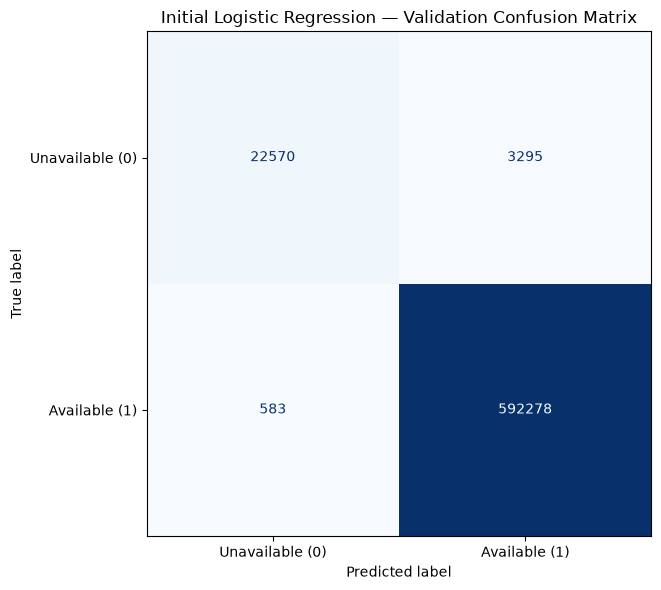

Correctly predicted unavailable: 22570
Missed unavailable observations: 3295
False unavailable predictions: 583
Correctly predicted available: 592278
Confusion matrix exported successfully.


In [76]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix using the shared prediction output
cm = confusion_matrix(
    lr_initial_predictions["y_true"],
    lr_initial_predictions["y_pred"],
    labels=[0, 1]
)

# Visualize classification results
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Unavailable (0)", "Available (1)"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Initial Logistic Regression — Validation Confusion Matrix"
)

plt.tight_layout()

# Save figure
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "logistic_regression_initial_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correctly predicted unavailable:", cm[0, 0])
print("Missed unavailable observations:", cm[0, 1])
print("False unavailable predictions:", cm[1, 0])
print("Correctly predicted available:", cm[1, 1])
print("Confusion matrix exported successfully.")



## 4.4. Class-0 Precision-Recall Curve

**Objective:** Examine the trade-off between precision and recall for unavailable charging stations across different classification thresholds.

The Logistic Regression pipeline outputs P(Available = 1). Therefore, Class-0 probabilities are calculated as 1 - P(Available = 1).

Average Precision for Class 0 (AP₀) summarizes the precision-recall curve and is used as the primary model comparison metric on seen validation stations.

This analysis is descriptive only. Classification threshold optimization will be performed separately using the approved internal Threshold period.


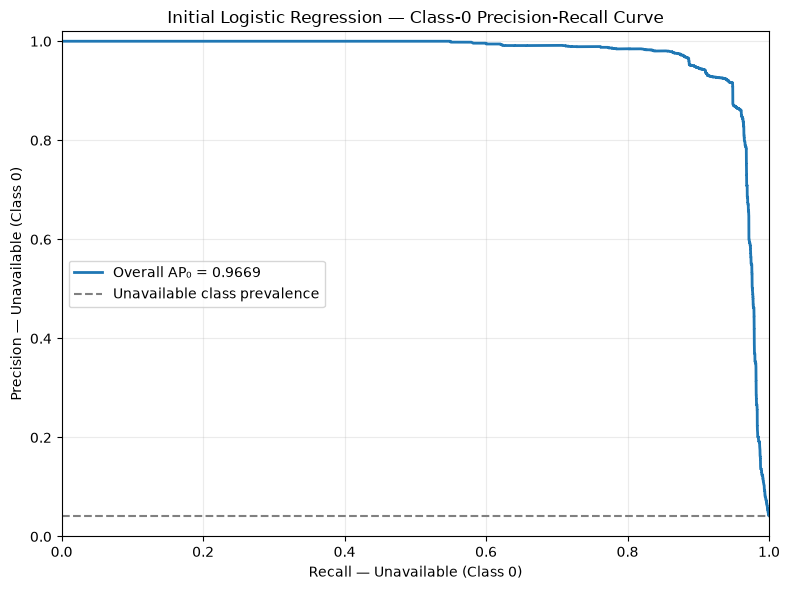

Overall Class-0 AP: 0.96694
Seen-station Class-0 AP: 0.967384
PR curve exported successfully.


In [77]:

from sklearn.metrics import precision_recall_curve, average_precision_score

# Use the shared prediction output
y_true_val = lr_initial_predictions["y_true"].to_numpy()
y_prob_available = lr_initial_predictions["y_prob"].to_numpy()

# Convert probabilities and targets for Class 0 (Unavailable)
y_true_unavailable = (y_true_val == 0).astype(int)
y_prob_unavailable = 1.0 - y_prob_available

# Calculate the precision-recall curve for Class 0
precision_0, recall_0, pr_thresholds = precision_recall_curve(
    y_true_unavailable,
    y_prob_unavailable
)

# Overall Class-0 Average Precision
ap_0_overall = average_precision_score(
    y_true_unavailable,
    y_prob_unavailable
)

# Identify seen stations using the shared training station IDs
seen_mask = lr_initial_predictions["station_id"].isin(
    training_station_ids
).to_numpy()

ap_0_seen = average_precision_score(
    y_true_unavailable[seen_mask],
    y_prob_unavailable[seen_mask]
)

# Visualize the precision-recall curve
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    recall_0,
    precision_0,
    linewidth=2,
    label=f"Overall AP₀ = {ap_0_overall:.4f}"
)

ax.axhline(
    y_true_unavailable.mean(),
    linestyle="--",
    color="gray",
    label="Unavailable class prevalence"
)

ax.set_xlabel("Recall — Unavailable (Class 0)")
ax.set_ylabel("Precision — Unavailable (Class 0)")
ax.set_title(
    "Initial Logistic Regression — Class-0 Precision-Recall Curve"
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "logistic_regression_initial_pr_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Verify consistency with shared evaluation results
assert np.isclose(
    ap_0_overall,
    lr_initial_overall["ap_0"].iloc[0],
    atol=1e-6
)

seen_ap_reference = lr_initial_by_station_group.loc[
    lr_initial_by_station_group["evaluation_group"] == "seen",
    "ap_0"
].iloc[0]

assert np.isclose(
    ap_0_seen,
    seen_ap_reference,
    atol=1e-6
)

print("Overall Class-0 AP:", round(ap_0_overall, 6))
print("Seen-station Class-0 AP:", round(ap_0_seen, 6))
print("PR curve exported successfully.")



### Key Findings — Precision-Recall Analysis

- The initial model achieved an overall Class-0 Average Precision of 0.966940.
- Seen-station Class-0 Average Precision was 0.967384, establishing the primary comparison baseline.
- Precision remains high across much of the recall range, indicating strong ranking performance for unavailable observations.
- Precision decreases sharply near maximum recall, reflecting the trade-off between detecting additional unavailable cases and generating false alarms.
- No decision threshold was selected using the validation precision-recall curve.



## 4.5. Initial Probability Calibration Analysis

**Objective:** Evaluate the reliability of the initial Logistic Regression availability probabilities.

A well-calibrated model produces probabilities that correspond to observed outcome frequencies. For example, among observations assigned an availability probability of approximately 0.80, around 80% should be available.

Calibration is examined using a reliability diagram and the Brier Score.

This analysis is descriptive only. Any probability calibration method will be fitted and selected using the approved internal chronological periods, without fitting on the shared validation dataset.


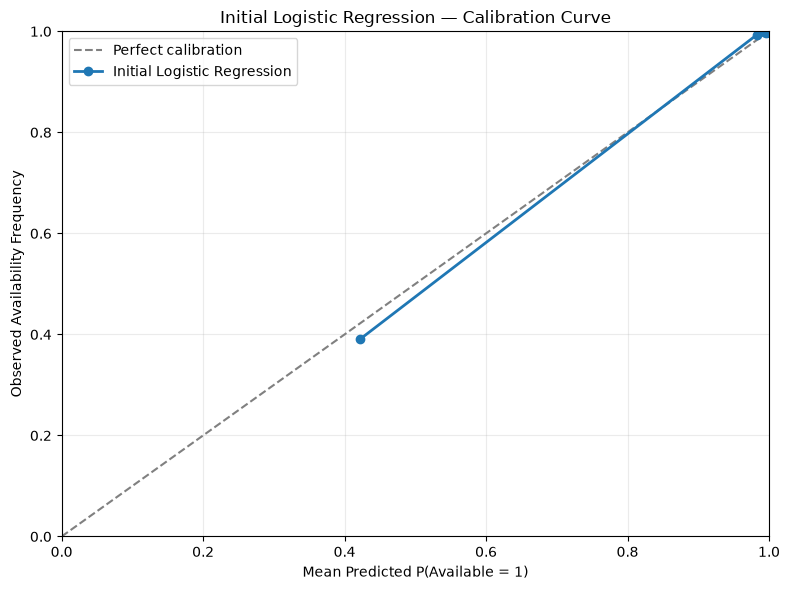

Initial Brier Score: 0.005097
Calibration bins: 15
Calibration curve exported successfully.


In [78]:

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Use the initial validation predictions
y_true_cal = lr_initial_predictions["y_true"].to_numpy()
y_prob_cal = lr_initial_predictions["y_prob"].to_numpy()

# Calculate the reliability curve for P(Available = 1)
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_true_cal,
    y_prob_cal,
    n_bins=15,
    strategy="quantile"
)

# Calculate probability quality
initial_brier = brier_score_loss(
    y_true_cal,
    y_prob_cal
)

# Plot reliability diagram
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

ax.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    linewidth=2,
    label="Initial Logistic Regression"
)

ax.set_xlabel("Mean Predicted P(Available = 1)")
ax.set_ylabel("Observed Availability Frequency")
ax.set_title(
    "Initial Logistic Regression — Calibration Curve"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "logistic_regression_initial_calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Verify consistency with shared evaluation results
assert np.isclose(
    initial_brier,
    lr_initial_overall["brier_score"].iloc[0],
    atol=1e-6
)

print("Initial Brier Score:", round(initial_brier, 6))
print("Calibration bins:", len(mean_predicted_value))
print("Calibration curve exported successfully.")



### Key Findings — Initial Calibration Analysis

- The initial Logistic Regression model achieved a validation Brier Score of 0.005097.
- The reliability curve generally follows the ideal calibration reference.
- Most calibration bins are concentrated near high availability probabilities because Class 1 dominates the validation dataset.
- Some deviations from perfect calibration remain, especially at lower predicted availability probabilities.
- These results do not establish whether post-hoc calibration is beneficial.
- Sigmoid and isotonic calibration will be assessed using the approved internal calibration period during Step 5.



## 4.6. Initial Logistic Regression Coefficient Analysis

**Objective:** Examine the learned coefficients of the initial Logistic Regression model to understand feature contributions and identify potential redundancy.

Positive coefficients increase the model's log-odds of predicting Class 1 (Available), while negative coefficients decrease them.

Numerical features are standardized, and station identifiers are one-hot encoded. Coefficient magnitudes should therefore be interpreted with awareness of preprocessing, correlated features, and regularization.

The analysis is descriptive and does not imply causal relationships.


In [79]:

# Extract fitted preprocessing and classifier components
fitted_preprocessor = lr_initial_pipeline.named_steps[
    "preprocessing"
]

fitted_classifier = lr_initial_pipeline.named_steps[
    "classifier"
]

# Get feature names after encoding and scaling
encoded_feature_names = fitted_preprocessor.get_feature_names_out()

# Extract logistic regression coefficients
coefficients = fitted_classifier.coef_[0]

assert len(encoded_feature_names) == len(coefficients)
assert len(coefficients) == 106

# Build coefficient analysis table
lr_coefficients_df = pd.DataFrame({
    "feature": encoded_feature_names,
    "coefficient": coefficients,
})

lr_coefficients_df["absolute_coefficient"] = (
    lr_coefficients_df["coefficient"].abs()
)

lr_coefficients_df = lr_coefficients_df.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

print("Encoded features:", len(lr_coefficients_df))

print("\nTop 15 coefficients by absolute magnitude:")
display(lr_coefficients_df.head(15))

print("\nNumerical feature coefficients:")
lr_numerical_coefficients = lr_coefficients_df[
    lr_coefficients_df["feature"].str.startswith("numerical__")
].copy()

display(lr_numerical_coefficients)

# Export coefficient table
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

lr_coefficients_df.to_csv(
    TABLES_DIR / "logistic_regression_initial_coefficients.csv",
    index=False
)

print("Coefficient analysis exported successfully.")


Encoded features: 106

Top 15 coefficients by absolute magnitude:


,feature,coefficient,absolute_coefficient
0,categorical__station_id_1775,-8.234555,8.234555
1,categorical__station_id_1882,-7.947916,7.947916
2,categorical__station_id_1720,3.900699,3.900699
3,categorical__station_id_1864,3.858714,3.858714
4,categorical__station_id_1758,-3.711577,3.711577
5,categorical__station_id_1717,3.517350,3.517350
6,categorical__station_id_1946,3.300376,3.300376
7,categorical__station_id_1763,-3.017440,3.017440
8,categorical__station_id_1857,2.187081,2.187081
9,categorical__station_id_1786,2.185360,2.185360



Numerical feature coefficients:


,feature,coefficient,absolute_coefficient
17,numerical__occupancy_rate,-1.637957,1.637957
26,numerical__current_idle,-1.375450,1.375450
27,numerical__is_weekend,1.272372,1.272372
33,numerical__station_capacity,-1.112918,1.112918
46,numerical__day_of_week,-0.914958,0.914958
51,numerical__idle_lag_10,0.808076,0.808076
59,numerical__idle_lag_5,0.704307,0.704307
60,numerical__idle_lag_15,0.690339,0.690339
67,numerical__idle_lag_120,0.550790,0.550790
80,numerical__idle_lag_30,0.367463,0.367463


Coefficient analysis exported successfully.



### Key Findings — Initial Coefficient Analysis

- The initial Logistic Regression model contains 106 encoded features: 91 station indicator features and 15 numerical features.
- Station-specific coefficients have the largest absolute magnitudes, suggesting that the model learns substantial station-specific patterns.
- The occupancy rate has a negative coefficient, consistent with lower predicted availability at higher occupancy, conditional on other features.
- The negative coefficient for current idle chargers is counterintuitive and may reflect multicollinearity among occupancy, capacity, current charger counts, and historical idle features.
- Coefficient magnitudes alone do not establish feature importance or causal effects.
- Feature redundancy and reduced-feature configurations will be investigated during Step 5 optimization.



## 4.7. Numerical Coefficient Visualization

**Objective:** Visualize the direction and magnitude of the initial Logistic Regression numerical coefficients.

The chart includes all 15 standardized numerical features and excludes station-specific one-hot encoded indicators to improve interpretability.

Coefficient signs describe conditional associations with predicted availability, not causal effects or standalone feature importance.


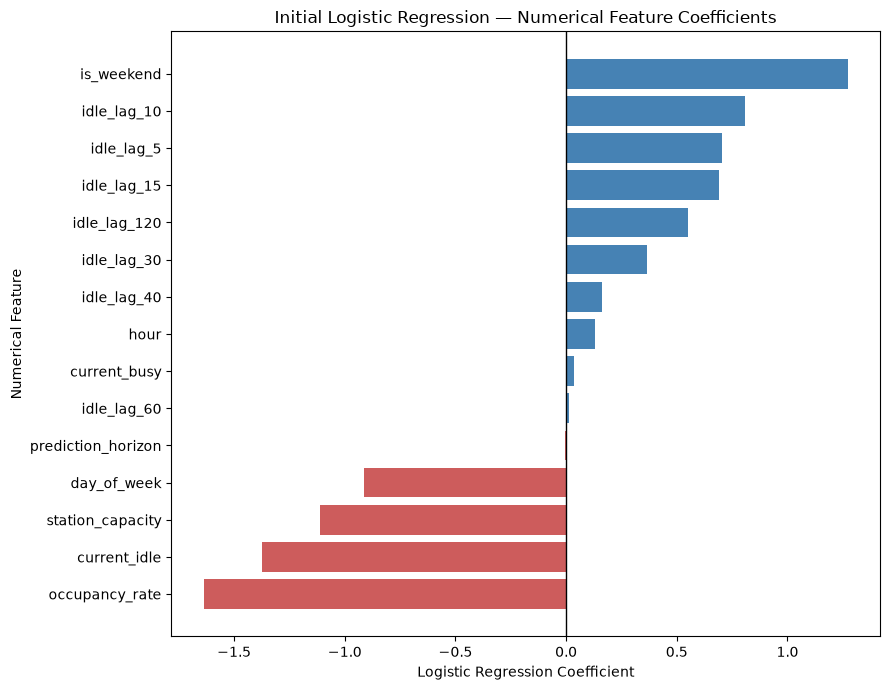

Numerical coefficients visualized: 15
Coefficient visualization exported successfully.


In [80]:

# Prepare numerical coefficients for visualization
plot_coefficients = lr_numerical_coefficients.copy()

plot_coefficients["feature"] = (
    plot_coefficients["feature"]
    .str.replace("numerical__", "", regex=False)
)

plot_coefficients = plot_coefficients.sort_values(
    "coefficient",
    ascending=True
)

# Plot all numerical coefficients
fig, ax = plt.subplots(figsize=(9, 7))

colors = [
    "steelblue" if coef >= 0 else "indianred"
    for coef in plot_coefficients["coefficient"]
]

ax.barh(
    plot_coefficients["feature"],
    plot_coefficients["coefficient"],
    color=colors
)

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Logistic Regression Coefficient")
ax.set_ylabel("Numerical Feature")
ax.set_title(
    "Initial Logistic Regression — Numerical Feature Coefficients"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "logistic_regression_initial_numerical_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Numerical coefficients visualized:", len(plot_coefficients))
print("Coefficient visualization exported successfully.")



## 4.8. Initial Logistic Regression Error Analysis

**Objective:** Identify and analyze classification errors made by the initial Logistic Regression model on the shared validation dataset.

The analysis focuses on:

- Overall counts of correct and incorrect predictions.
- Missed unavailable observations across the 30-, 40-, and 60-minute prediction horizons.
- Station-level error concentration.
- Differences between seen and unseen stations.

**Error definitions:**

- **Missed unavailable:** Actual Class 0, predicted Class 1.
- **False unavailable:** Actual Class 1, predicted Class 0.

Missed unavailable observations are particularly important because they represent charging stations incorrectly predicted to have available chargers.

This analysis is descriptive. No model parameters or decision thresholds are optimized using validation observations.


In [81]:

# 4.8.1 — Overall Error Summary

# Use the initial Logistic Regression validation predictions
error_df = lr_initial_predictions.copy()

# Verify the correct dataset and model version
assert len(error_df) == 618_726
assert (error_df["model_name"] == "logistic_regression").all()
assert (error_df["model_version"] == "initial").all()

# Define classification outcomes
error_df["correct_unavailable"] = (
    (error_df["y_true"] == 0) &
    (error_df["y_pred"] == 0)
).astype(int)

error_df["missed_unavailable"] = (
    (error_df["y_true"] == 0) &
    (error_df["y_pred"] == 1)
).astype(int)

error_df["false_unavailable"] = (
    (error_df["y_true"] == 1) &
    (error_df["y_pred"] == 0)
).astype(int)

error_df["correct_available"] = (
    (error_df["y_true"] == 1) &
    (error_df["y_pred"] == 1)
).astype(int)

# Create overall error summary
overall_error_summary = pd.DataFrame({
    "Metric": [
        "Correctly Predicted Unavailable",
        "Missed Unavailable Observations",
        "False Unavailable Predictions",
        "Correctly Predicted Available"
    ],
    "Count": [
        int(error_df["correct_unavailable"].sum()),
        int(error_df["missed_unavailable"].sum()),
        int(error_df["false_unavailable"].sum()),
        int(error_df["correct_available"].sum())
    ]
})

# Validate against the shared evaluation results
assert overall_error_summary["Count"].sum() == 618_726
assert error_df["missed_unavailable"].sum() == 3295
assert error_df["false_unavailable"].sum() == 583

display(overall_error_summary)

# Export overall error summary
overall_error_summary.to_csv(
    TABLES_DIR / "logistic_regression_initial_error_summary.csv",
    index=False
)

print("Overall error analysis: PASSED")
print("Overall error summary exported successfully.")


,Metric,Count
0,Correctly Predicted Unavailable,22570
1,Missed Unavailable Observations,3295
2,False Unavailable Predictions,583
3,Correctly Predicted Available,592278


Overall error analysis: PASSED
Overall error summary exported successfully.


In [82]:

# 4.8.2 — Horizon-Level Error Analysis

horizon_error_summary = (
    error_df.groupby("prediction_horizon")
    .agg(
        observations=("y_true", "size"),
        actual_unavailable=("correct_unavailable", "sum"),
        missed_unavailable=("missed_unavailable", "sum"),
        false_unavailable=("false_unavailable", "sum"),
        correctly_predicted_unavailable=("correct_unavailable", "sum"),
        correctly_predicted_available=("correct_available", "sum")
    )
    .reset_index()
)

# Include both correct and missed unavailable observations
horizon_error_summary["actual_unavailable"] += (
    horizon_error_summary["missed_unavailable"]
)

horizon_error_summary["actual_available"] = (
    horizon_error_summary["correctly_predicted_available"]
    + horizon_error_summary["false_unavailable"]
)

# Calculate error rates
horizon_error_summary["missed_unavailable_rate (%)"] = (
    100
    * horizon_error_summary["missed_unavailable"]
    / horizon_error_summary["actual_unavailable"]
).round(2)

horizon_error_summary["false_unavailable_rate (%)"] = (
    100
    * horizon_error_summary["false_unavailable"]
    / horizon_error_summary["actual_available"]
).round(2)

# Arrange columns
horizon_error_summary = horizon_error_summary[
    [
        "prediction_horizon",
        "observations",
        "actual_unavailable",
        "actual_available",
        "correctly_predicted_unavailable",
        "missed_unavailable",
        "false_unavailable",
        "correctly_predicted_available",
        "missed_unavailable_rate (%)",
        "false_unavailable_rate (%)"
    ]
]

# Validate totals
assert horizon_error_summary["observations"].sum() == 618_726
assert horizon_error_summary["missed_unavailable"].sum() == 3295
assert horizon_error_summary["false_unavailable"].sum() == 583

display(horizon_error_summary)

# Export results
horizon_error_summary.to_csv(
    TABLES_DIR / "logistic_regression_initial_error_by_horizon.csv",
    index=False
)

print("Horizon-level error analysis: PASSED")
print("Horizon-level error summary exported successfully.")


,prediction_horizon,observations,actual_unavailable,actual_available,correctly_predicted_unavailable,missed_unavailable,false_unavailable,correctly_predicted_available,missed_unavailable_rate (%),false_unavailable_rate (%)
0,30,206482,8635,197847,7576,1059,149,197698,12.26,0.08
1,40,206302,8625,197677,7534,1091,186,197491,12.65,0.09
2,60,205942,8605,197337,7460,1145,248,197089,13.31,0.13


Horizon-level error analysis: PASSED
Horizon-level error summary exported successfully.


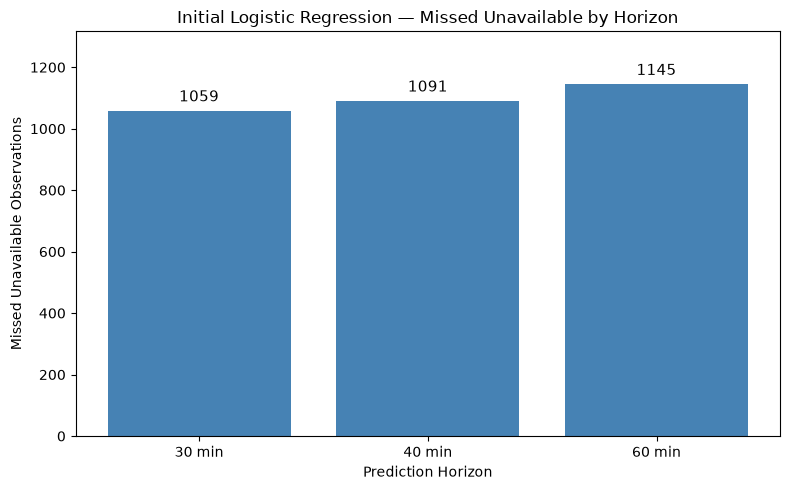

Horizon-level error visualization: PASSED
Figure exported successfully.


In [83]:

# 4.8.3 — Horizon-Level Error Visualization

fig, ax = plt.subplots(figsize=(8, 5))

horizon_labels = (
    horizon_error_summary["prediction_horizon"].astype(str)
    + " min"
)

missed_counts = horizon_error_summary[
    "missed_unavailable"
]

bars = ax.bar(
    horizon_labels,
    missed_counts,
    color="steelblue"
)

# Display missed unavailable counts above the bars
ax.bar_label(
    bars,
    padding=4,
    fontsize=11
)

ax.set_title(
    "Initial Logistic Regression — Missed Unavailable by Horizon"
)
ax.set_xlabel("Prediction Horizon")
ax.set_ylabel("Missed Unavailable Observations")

ax.set_ylim(
    0,
    missed_counts.max() * 1.15
)

plt.tight_layout()

# Export figure
plt.savefig(
    FIGURES_DIR / "logistic_regression_initial_missed_unavailable_by_horizon.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Horizon-level error visualization: PASSED")
print("Figure exported successfully.")


In [84]:

# 4.8.4 — Station-Level Error Analysis

# Calculate classification errors for each station
station_error_summary = (
    error_df.groupby("station_id")
    .agg(
        observations=("y_true", "size"),
        actual_unavailable=("missed_unavailable", "sum"),
        correctly_predicted_unavailable=("correct_unavailable", "sum"),
        missed_unavailable=("missed_unavailable", "sum"),
        false_unavailable=("false_unavailable", "sum")
    )
    .reset_index()
)

# Include correctly predicted unavailable observations
station_error_summary["actual_unavailable"] += (
    station_error_summary["correctly_predicted_unavailable"]
)

# Calculate missed unavailable rates
station_error_summary["missed_unavailable_rate (%)"] = np.where(
    station_error_summary["actual_unavailable"] > 0,
    100 * station_error_summary["missed_unavailable"]
    / station_error_summary["actual_unavailable"],
    np.nan
)

station_error_summary["missed_unavailable_rate (%)"] = (
    station_error_summary["missed_unavailable_rate (%)"].round(2)
)

# Identify seen and unseen stations
station_error_summary["station_group"] = np.where(
    station_error_summary["station_id"].isin(training_station_ids),
    "seen",
    "unseen"
)

# Rank stations with at least five actual unavailable observations
top_missed_unavailable_stations = (
    station_error_summary.loc[
        station_error_summary["actual_unavailable"] >= 5
    ]
    .sort_values(
        ["missed_unavailable", "missed_unavailable_rate (%)"],
        ascending=[False, False]
    )
    .head(15)
    .reset_index(drop=True)
)

# Validate station coverage and error totals
assert len(station_error_summary) == 90
assert station_error_summary["missed_unavailable"].sum() == 3295
assert station_error_summary["false_unavailable"].sum() == 583

assert set(
    station_error_summary.loc[
        station_error_summary["station_group"] == "unseen",
        "station_id"
    ]
) == {1948}

print("Top 15 stations by missed unavailable observations:")
display(top_missed_unavailable_stations)

print("\nUnseen station 1948:")
display(
    station_error_summary.loc[
        station_error_summary["station_id"] == 1948
    ]
)

# Export station-level tables
station_error_summary.to_csv(
    TABLES_DIR / "logistic_regression_initial_error_by_station.csv",
    index=False
)

top_missed_unavailable_stations.to_csv(
    TABLES_DIR / "logistic_regression_initial_top_missed_unavailable_stations.csv",
    index=False
)

print("Station-level error analysis: PASSED")
print("Station-level error tables exported successfully.")


Top 15 stations by missed unavailable observations:


,station_id,observations,actual_unavailable,correctly_predicted_unavailable,missed_unavailable,false_unavailable,missed_unavailable_rate (%),station_group
0,1751,6886,3031,1762,1269,26,41.87,seen
1,1879,6886,771,101,670,106,86.90,seen
2,1796,6886,357,0,357,0,100.00,seen
3,1888,6886,774,528,246,102,31.78,seen
4,1763,6886,2352,2166,186,186,7.91,seen
5,1802,6886,108,0,108,0,100.00,seen
6,1897,6886,102,0,102,0,100.00,seen
7,1777,6886,54,10,44,32,81.48,seen
8,1797,6886,201,163,38,20,18.91,seen
9,1758,6886,3865,3827,38,64,0.98,seen



Unseen station 1948:


,station_id,observations,actual_unavailable,correctly_predicted_unavailable,missed_unavailable,false_unavailable,missed_unavailable_rate (%),station_group
77,1948,5872,12,0,12,3,100.0,unseen


Station-level error analysis: PASSED
Station-level error tables exported successfully.


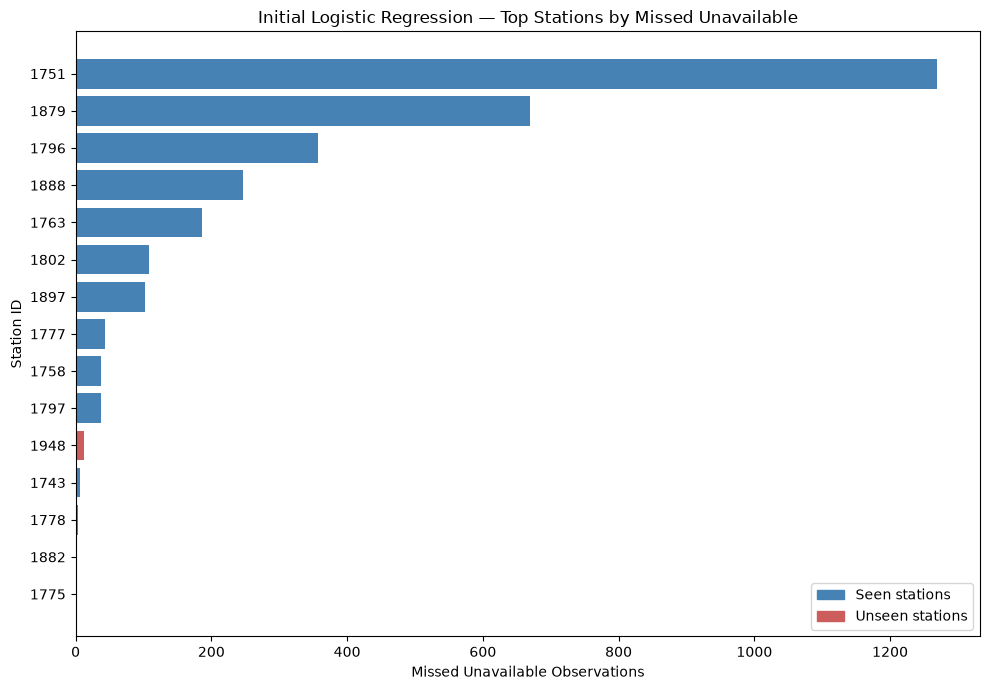

Station-level error visualization: PASSED
Figure exported successfully.


In [85]:

# 4.8.5 — Station-Level Error Visualization

# Sort the top stations for horizontal visualization
plot_station_errors = top_missed_unavailable_stations.sort_values(
    "missed_unavailable",
    ascending=True
)

# Highlight unseen stations separately
bar_colors = [
    "indianred" if group == "unseen" else "steelblue"
    for group in plot_station_errors["station_group"]
]

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    plot_station_errors["station_id"].astype(str),
    plot_station_errors["missed_unavailable"],
    color=bar_colors
)

ax.set_title(
    "Initial Logistic Regression — Top Stations by Missed Unavailable"
)
ax.set_xlabel("Missed Unavailable Observations")
ax.set_ylabel("Station ID")

# Add a legend for seen/unseen stations
from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="steelblue", label="Seen stations"),
        Patch(color="indianred", label="Unseen stations")
    ],
    loc="lower right"
)

plt.tight_layout()

# Export figure
plt.savefig(
    FIGURES_DIR / "logistic_regression_initial_top_missed_unavailable_stations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Station-level error visualization: PASSED")
print("Figure exported successfully.")



### Key Findings — Initial Error Analysis

- The initial Logistic Regression model produced 3,295 missed unavailable observations and 583 false unavailable predictions across the validation dataset.
- Missed unavailable observations are the most operationally critical errors because they may lead users to charging stations without available chargers.
- The missed unavailable rate increased from 12.26% at the 30-minute horizon to 13.31% at the 60-minute horizon.
- Classification errors were concentrated in specific stations. Stations 1751, 1879, and 1796 accounted for 2,296 missed unavailable observations, approximately 69.7% of all missed unavailable cases.
- Station 1751 had 1,269 missed unavailable observations, while station 1879 had a missed unavailable rate of 86.90%.
- Station 1796 had a 100% missed unavailable rate across 357 actual unavailable observations, indicating difficulty detecting unavailable states even at a previously seen station.
- The unseen station 1948 had 12 missed unavailable observations and a 100% missed unavailable rate. This result should be interpreted cautiously because the number of unavailable observations was small.
- Station-specific weaknesses and horizon-related performance degradation should be investigated during feature selection and threshold optimization.
- No model fitting or optimization decisions were made using validation observations.



## 4.9. Initial Findings & Conclusion

### Model Development Summary

The initial Logistic Regression model was successfully developed using the shared VoltAhead preprocessing pipeline and all 16 candidate input features.

- **Model:** Logistic Regression with L2 regularization
- **Regularization strength:** C = 1.0
- **Class weighting:** None
- **Initial classification threshold:** 0.5
- **Training period:** December 1–23, 2022
- **Training observations:** 1,790,062
- **Validation observations:** 618,726
- **Encoded features:** 106
- **Training time:** 2.67 seconds
- **Validation inference time:** 0.27 seconds

### Initial Validation Performance

| Metric | Result |
|---|---:|
| Accuracy | 0.993732 |
| Balanced Accuracy | 0.935812 |
| Class-0 Precision | 0.974820 |
| Class-0 Recall | 0.872608 |
| Class-0 F1 | 0.920886 |
| ROC-AUC | 0.991961 |
| Overall Class-0 AP | 0.966940 |
| **Seen-station Class-0 AP** | **0.967384** |
| Brier Score | 0.005097 |

The initial model achieved strong overall validation performance. However, accuracy alone is insufficient because the dataset is highly imbalanced toward available charging stations.

### Main Findings

**1. Unavailable Station Detection**

The model correctly identified 22,570 unavailable observations but missed 3,295 unavailable observations. These errors are operationally important because they may lead users to stations without available chargers.

**2. Prediction Horizon**

Class-0 detection performance decreased as the prediction horizon increased. The missed unavailable rate increased from 12.26% at 30 minutes to 13.31% at 60 minutes.

**3. Seen vs. Unseen Stations**

The primary model comparison metric, seen-station AP₀, was 0.967384.

The unseen station (1948) had 5,872 validation observations, including 12 unavailable observations. The model failed to detect all 12 unavailable cases, indicating a potential generalization limitation.

**4. Probability Quality**

The initial model achieved a Brier Score of 0.005097. Its reliability curve generally followed the ideal calibration reference, although deviations remained.

**5. Feature Interpretation**

Station-specific coefficients had the largest absolute magnitudes. Correlated numerical features, including current idle chargers, station capacity, and occupancy rate, showed coefficients that require further investigation.

**6. Station-Level Errors**

Stations 1751, 1879, and 1796 accounted for approximately 69.7% of missed unavailable observations. This indicates that classification errors are concentrated in specific stations.

### Limitations

- Unavailable-class detection is weaker than overall accuracy suggests.
- Performance decreases at longer prediction horizons.
- Certain seen stations have high missed unavailable rates.
- The unseen station has very few unavailable observations, limiting conclusions about generalization.
- Correlated numerical features may affect coefficient stability and interpretation.
- The initial classification threshold has not been optimized.

### Conclusion

The initial Logistic Regression model provides a strong and computationally efficient baseline for EV charging station availability prediction.

The primary seen-station Class-0 Average Precision of **0.967384** establishes the reference value for subsequent model comparison.

Step 5 will investigate hyperparameter tuning, class weighting, feature redundancy, probability calibration, and classification threshold optimization using the approved internal chronological splits.

The shared validation and test datasets will not be used for these optimization decisions.



# Step 5 — Logistic Regression Optimization

## 5.1. Hyperparameter Tuning Preparation

**Objective:** Prepare the approved internal chronological datasets for Logistic Regression hyperparameter optimization.

- Model Fit: December 1–23, 2022
- Tuning: December 24–29, 2022
- Calibration: December 30, 2022 – January 2, 2023
- Threshold Optimization: January 3–5, 2023

Hyperparameter candidates will be fitted exclusively on the Model Fit period and compared using Class-0 Average Precision (AP₀) on the internal Tuning period.

The shared validation and test datasets will not be used for hyperparameter selection.


In [86]:

# 5.1 — Hyperparameter Tuning Preparation

# Reuse the complete approved Model Fit dataset
X_tune_fit = internal_datasets["Model Fit"][FEATURE_COLUMNS]
y_tune_fit = internal_datasets["Model Fit"]["target"].astype(int)

# Prepare the separate internal Tuning dataset
tuning_df = internal_datasets["Tuning"]

X_tune = tuning_df[FEATURE_COLUMNS]
y_tune = tuning_df["target"].astype(int)

# Validate dataset sizes and feature consistency
assert len(X_tune_fit) == 1_790_062
assert len(X_tune) == 466_897

assert X_tune_fit.columns.tolist() == FEATURE_COLUMNS
assert X_tune.columns.tolist() == FEATURE_COLUMNS

assert set(y_tune_fit.unique()) == {0, 1}
assert set(y_tune.unique()) == {0, 1}

# Verify chronological separation
assert (
    internal_datasets["Model Fit"]["target_time"].max()
    < tuning_df["time"].min()
)

print("Model Fit observations:", len(X_tune_fit))
print("Tuning observations:", len(X_tune))
print("Input features:", X_tune.shape[1])

print(
    "Model Fit unavailable rate:",
    round(100 * (y_tune_fit == 0).mean(), 2),
    "%"
)

print(
    "Tuning unavailable rate:",
    round(100 * (y_tune == 0).mean(), 2),
    "%"
)

print("Hyperparameter tuning preparation: PASSED")


Model Fit observations: 1790062
Tuning observations: 466897
Input features: 16
Model Fit unavailable rate: 4.91 %
Tuning unavailable rate: 4.44 %
Hyperparameter tuning preparation: PASSED



## 5.2. Hyperparameter Tuning — Regularization Strength and Class Weighting

**Objective:** Compare Logistic Regression configurations using the approved internal Model Fit and Tuning periods.

The experiment evaluates four regularization strengths (`C = 0.01, 0.1, 1, 10`) with two class-weighting strategies (`None` and `balanced`).

All candidates use L2 regularization, the `lbfgs` solver, and the same shared preprocessing pipeline.

The primary hyperparameter selection metric is Class-0 Average Precision (AP₀) on the internal Tuning period.

Training time, inference time, Class-0 F1, Class-0 recall, and Brier Score are also recorded for comparison.

The shared validation and test datasets remain excluded from hyperparameter selection.


In [87]:

# 5.2 — Logistic Regression Hyperparameter Tuning

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss
)
from sklearn.exceptions import ConvergenceWarning
import warnings

# Define the approved search space
c_values = [0.01, 0.1, 1.0, 10.0]
class_weights = [None, "balanced"]

tuning_results = []

for class_weight in class_weights:
    for c_value in c_values:

        # Build a fresh preprocessing + Logistic Regression pipeline
        candidate_pipeline = Pipeline([
            ("preprocessing", clone(lr_preprocessor)),
            ("classifier", LogisticRegression(
                C=c_value,
                l1_ratio=0,
                solver="lbfgs",
                max_iter=1000,
                class_weight=class_weight,
                random_state=42
            ))
        ])

        # Fit exclusively on the Model Fit period
        start_train = time.perf_counter()

        with warnings.catch_warnings(record=True) as caught_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            candidate_pipeline.fit(X_tune_fit, y_tune_fit)

        training_seconds = time.perf_counter() - start_train

        convergence_warnings = [
            warning for warning in caught_warnings
            if issubclass(warning.category, ConvergenceWarning)
        ]

        # Predict probabilities on the internal Tuning period
        start_inference = time.perf_counter()

        tuning_prob_available = candidate_pipeline.predict_proba(
            X_tune
        )[:, 1]

        inference_seconds = time.perf_counter() - start_inference

        # Apply the initial threshold only for secondary metrics
        tuning_pred = (tuning_prob_available >= 0.5).astype(int)

        # Compute Class-0 AP from P(Unavailable)
        ap_0 = average_precision_score(
            (y_tune.to_numpy() == 0).astype(int),
            1 - tuning_prob_available
        )

        tuning_results.append({
            "C": c_value,
            "class_weight": str(class_weight),
            "solver": "lbfgs",
            "regularization": "l2",
            "ap_0": ap_0,
            "f1_0": f1_score(
                y_tune, tuning_pred, pos_label=0, zero_division=0
            ),
            "recall_0": recall_score(
                y_tune, tuning_pred, pos_label=0, zero_division=0
            ),
            "precision_0": precision_score(
                y_tune, tuning_pred, pos_label=0, zero_division=0
            ),
            "brier_score": brier_score_loss(
                y_tune, tuning_prob_available
            ),
            "training_seconds": training_seconds,
            "inference_seconds": inference_seconds,
            "converged": len(convergence_warnings) == 0
        })

        print(
            f"C={c_value}, class_weight={class_weight} | "
            f"AP_0={ap_0:.6f} | "
            f"Converged={len(convergence_warnings) == 0}"
        )

# Rank candidates by the primary internal tuning metric
lr_tuning_results_df = pd.DataFrame(tuning_results).sort_values(
    "ap_0",
    ascending=False
).reset_index(drop=True)

display(lr_tuning_results_df)

# Save tuning results
lr_tuning_results_df.to_csv(
    TABLES_DIR / "logistic_regression_hyperparameter_tuning.csv",
    index=False
)

print("Hyperparameter tuning experiment completed.")
print("Results exported successfully.")


C=0.01, class_weight=None | AP_0=0.983628 | Converged=True
C=0.1, class_weight=None | AP_0=0.982405 | Converged=True
C=1.0, class_weight=None | AP_0=0.981552 | Converged=True
C=10.0, class_weight=None | AP_0=0.980704 | Converged=True
C=0.01, class_weight=balanced | AP_0=0.975125 | Converged=True
C=0.1, class_weight=balanced | AP_0=0.971194 | Converged=True
C=1.0, class_weight=balanced | AP_0=0.970869 | Converged=True
C=10.0, class_weight=balanced | AP_0=0.970735 | Converged=True


,C,class_weight,solver,regularization,ap_0,f1_0,recall_0,precision_0,brier_score,training_seconds,inference_seconds,converged
0,0.01,None,lbfgs,l2,0.983628,0.946748,0.907121,0.989995,0.003217,2.085966,0.128851,True
1,0.10,None,lbfgs,l2,0.982405,0.946475,0.906928,0.989628,0.003177,2.029131,0.114675,True
2,1.00,None,lbfgs,l2,0.981552,0.953224,0.919328,0.989715,0.003121,2.204592,0.110261,True
3,10.00,None,lbfgs,l2,0.980704,0.946629,0.907121,0.989735,0.003407,1.810505,0.103921,True
4,0.01,balanced,lbfgs,l2,0.975125,0.900943,0.951607,0.855402,0.008825,2.142938,0.106454,True
5,0.10,balanced,lbfgs,l2,0.971194,0.895833,0.951655,0.846197,0.009180,2.874728,0.116521,True
6,1.00,balanced,lbfgs,l2,0.970869,0.895386,0.951655,0.845399,0.009225,2.481939,0.112391,True
7,10.00,balanced,lbfgs,l2,0.970735,0.894188,0.951655,0.843266,0.009180,2.743413,0.112900,True


Hyperparameter tuning experiment completed.
Results exported successfully.



### Key Findings — Hyperparameter Tuning

- Eight Logistic Regression configurations were evaluated using the approved internal Model Fit and Tuning periods.
- All configurations completed training without convergence warnings.
- The highest Class-0 Average Precision was 0.983628, achieved with L2 regularization, C = 0.01, and class_weight = None.
- Stronger regularization generally improved Class-0 Average Precision within the tested configurations.
- Balanced class weighting increased Class-0 recall but reduced precision, F1, Average Precision, and probability quality.
- The C = 1.0, class_weight = None configuration achieved the highest Class-0 F1 at the fixed 0.5 threshold, but C = 0.01 was preferred based on the predefined AP₀ selection criterion.
- The best configuration from this experiment will be compared with additional regularization and feature-set alternatives before final model selection.
- No shared validation or test observations were used for hyperparameter selection.



## 5.3. Regularization and Solver Comparison

**Objective:** Compare L2, L1, and Elastic Net regularization for Logistic Regression using the approved internal chronological datasets.

The experiment uses C = 0.01 and class_weight = None, based on the best configuration from the previous tuning experiment.

Configurations:

- L2 regularization with the lbfgs solver.
- L1 regularization with the saga solver.
- Elastic Net regularization with the saga solver and an L1 ratio of 0.5.

All models are trained exclusively on the Model Fit period and compared using Class-0 Average Precision on the internal Tuning period.

The experiment also records convergence status and the number of nonzero coefficients to investigate model sparsity.

The shared validation and test datasets remain excluded from model selection.


In [88]:

# 5.3 — Regularization and Solver Comparison

regularization_configs = [
    {
        "regularization": "l2",
        "solver": "lbfgs",
        "l1_ratio": 0.0
    },
    {
        "regularization": "l1",
        "solver": "saga",
        "l1_ratio": 1.0
    },
    {
        "regularization": "elastic_net",
        "solver": "saga",
        "l1_ratio": 0.5
    }
]

regularization_results = []

for config in regularization_configs:

    model = Pipeline([
        ("preprocessing", clone(lr_preprocessor)),
        ("classifier", LogisticRegression(
            C=0.01,
            l1_ratio=config["l1_ratio"],
            solver=config["solver"],
            max_iter=2000,
            tol=1e-3,
            class_weight=None,
            random_state=42
        ))
    ])

    # Fit exclusively on the Model Fit period
    start_train = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_tune_fit, y_tune_fit)

    train_seconds = time.perf_counter() - start_train

    convergence_warnings = [
        w for w in caught_warnings
        if issubclass(w.category, ConvergenceWarning)
    ]

    # Predict on the internal Tuning period
    start_inference = time.perf_counter()

    prob_available = model.predict_proba(X_tune)[:, 1]

    inference_seconds = time.perf_counter() - start_inference

    # Calculate Class-0 Average Precision
    ap_0 = average_precision_score(
        (y_tune.to_numpy() == 0).astype(int),
        1 - prob_available
    )

    # Analyze coefficient sparsity
    coefs = model.named_steps["classifier"].coef_[0]
    nonzero_coefs = int(np.count_nonzero(np.abs(coefs) > 1e-8))

    regularization_results.append({
        "regularization": config["regularization"],
        "solver": config["solver"],
        "C": 0.01,
        "l1_ratio": config["l1_ratio"],
        "ap_0": ap_0,
        "nonzero_coefficients": nonzero_coefs,
        "total_coefficients": len(coefs),
        "training_seconds": train_seconds,
        "inference_seconds": inference_seconds,
        "converged": len(convergence_warnings) == 0
    })

    print(
        f"{config['regularization']} | "
        f"solver={config['solver']} | "
        f"AP_0={ap_0:.6f} | "
        f"Nonzero={nonzero_coefs}/{len(coefs)} | "
        f"Converged={len(convergence_warnings) == 0}"
    )

lr_regularization_results_df = pd.DataFrame(
    regularization_results
).sort_values(
    "ap_0",
    ascending=False
).reset_index(drop=True)

display(lr_regularization_results_df)

# Export results
lr_regularization_results_df.to_csv(
    TABLES_DIR / "logistic_regression_regularization_comparison.csv",
    index=False
)

print("Regularization comparison completed.")
print("Results exported successfully.")


l2 | solver=lbfgs | AP_0=0.982883 | Nonzero=106/106 | Converged=True
l1 | solver=saga | AP_0=0.983325 | Nonzero=49/106 | Converged=True
elastic_net | solver=saga | AP_0=0.983595 | Nonzero=63/106 | Converged=True


,regularization,solver,C,l1_ratio,ap_0,nonzero_coefficients,total_coefficients,training_seconds,inference_seconds,converged
0,elastic_net,saga,0.01,0.5,0.983595,63,106,10.120426,0.120805,True
1,l1,saga,0.01,1.0,0.983325,49,106,8.140674,0.116763,True
2,l2,lbfgs,0.01,0.0,0.982883,106,106,1.201124,0.169343,True


Regularization comparison completed.
Results exported successfully.



### Key Findings — Regularization and Solver Comparison

- All three regularization configurations completed training without convergence warnings.
- Elastic Net achieved the highest Class-0 AP within this experiment (0.983595), followed by L1 (0.983325) and L2 (0.982883).
- L1 and Elastic Net produced substantially sparser models, with 49 and 63 nonzero coefficients respectively, compared with 106 for L2.
- L2 required the shortest training time, while SAGA-based configurations took longer.
- The best L2 result from Section 5.2 (AP₀ = 0.983628) remains marginally higher than the Elastic Net result.
- Since the experiments used different optimization tolerances, a controlled comparison is required before selecting a regularization method.
- No final model configuration has been selected at this stage.



## 5.4. Controlled Regularization Comparison

**Objective:** Re-evaluate L2, L1, and Elastic Net regularization using consistent convergence tolerance and evaluation settings.

All models use C = 0.01, class_weight = None, max_iter = 2000, tol = 1e-4, and random_state = 42.

The experiment compares Class-0 Average Precision on the approved internal Tuning dataset, alongside model sparsity, training time, and convergence status.

This controlled comparison supports regularization selection before feature redundancy experiments.


In [89]:

# 5.4 — Controlled Regularization Comparison

controlled_results = []

for config in regularization_configs:

    model = Pipeline([
        ("preprocessing", clone(lr_preprocessor)),
        ("classifier", LogisticRegression(
            C=0.01,
            l1_ratio=config["l1_ratio"],
            solver=config["solver"],
            max_iter=2000,
            tol=1e-4,
            class_weight=None,
            random_state=42
        ))
    ])

    start_time = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_tune_fit, y_tune_fit)

    training_seconds = time.perf_counter() - start_time

    convergence_warnings = [
        w for w in caught_warnings
        if issubclass(w.category, ConvergenceWarning)
    ]

    start_inference = time.perf_counter()
    prob_available = model.predict_proba(X_tune)[:, 1]
    inference_seconds = time.perf_counter() - start_inference

    ap_0 = average_precision_score(
        (y_tune.to_numpy() == 0).astype(int),
        1 - prob_available
    )

    coefficients = model.named_steps["classifier"].coef_[0]
    nonzero_count = int(np.count_nonzero(np.abs(coefficients) > 1e-8))

    controlled_results.append({
        "regularization": config["regularization"],
        "solver": config["solver"],
        "C": 0.01,
        "l1_ratio": config["l1_ratio"],
        "tolerance": 1e-4,
        "ap_0": ap_0,
        "nonzero_coefficients": nonzero_count,
        "training_seconds": training_seconds,
        "inference_seconds": inference_seconds,
        "converged": len(convergence_warnings) == 0
    })

    print(
        f"{config['regularization']} | "
        f"AP_0={ap_0:.6f} | "
        f"Nonzero={nonzero_count}/106 | "
        f"Converged={len(convergence_warnings) == 0}"
    )

lr_controlled_results_df = pd.DataFrame(
    controlled_results
).sort_values(
    "ap_0", ascending=False
).reset_index(drop=True)

display(lr_controlled_results_df)

lr_controlled_results_df.to_csv(
    TABLES_DIR / "logistic_regression_controlled_regularization.csv",
    index=False
)

print("Controlled regularization comparison completed.")


l2 | AP_0=0.983628 | Nonzero=106/106 | Converged=True
l1 | AP_0=0.983294 | Nonzero=45/106 | Converged=True
elastic_net | AP_0=0.983588 | Nonzero=63/106 | Converged=True


,regularization,solver,C,l1_ratio,tolerance,ap_0,nonzero_coefficients,training_seconds,inference_seconds,converged
0,l2,lbfgs,0.01,0.0,0.0001,0.983628,106,1.874118,0.107725,True
1,elastic_net,saga,0.01,0.5,0.0001,0.983588,63,136.415319,0.180958,True
2,l1,saga,0.01,1.0,0.0001,0.983294,45,97.475702,0.185689,True


Controlled regularization comparison completed.



### Key Findings — Controlled Regularization Comparison

- All three configurations completed training without convergence warnings using a common tolerance of 1e-4.
- L2 regularization achieved the highest internal Tuning Class-0 Average Precision (0.983628).
- Elastic Net achieved a nearly identical AP₀ of 0.983588 while retaining 63 of 106 nonzero coefficients.
- L1 achieved an AP₀ of 0.983294 with 45 nonzero coefficients.
- L2 required approximately 2.09 seconds to train, compared with 97.82 seconds for L1 and 135.79 seconds for Elastic Net.
- Although L1 and Elastic Net produced sparser models, neither improved AP₀ over L2.
- L2 regularization with C = 0.01 and class_weight = None is the preferred configuration for the subsequent feature redundancy experiments.
- Final model selection remains subject to the results of feature-set comparison.



## 5.5. Feature Redundancy Analysis

**Objective:** Investigate potential multicollinearity and redundancy among charger availability and station capacity features.

The analysis focuses on four variables:

- `current_idle`
- `current_busy`
- `station_capacity`
- `occupancy_rate`

Strong correlations or deterministic relationships may make Logistic Regression coefficients difficult to interpret and introduce redundant information.

The analysis uses only the approved Model Fit period. Feature removal decisions will be evaluated separately using the internal Tuning dataset.

No shared validation or test observations are used.


Feature correlation matrix:


,current_idle,current_busy,station_capacity,occupancy_rate
current_idle,1.0000,0.1824,0.9013,-0.2411
current_busy,0.1824,1.0000,0.5903,0.5867
station_capacity,0.9013,0.5903,1.0000,0.0605
occupancy_rate,-0.2411,0.5867,0.0605,1.0000



Potential deterministic relationships:


,Relationship,Matching observations (%)
0,station_capacity = current_idle + current_busy,100.0
1,occupancy_rate = current_busy / station_capacity,100.0


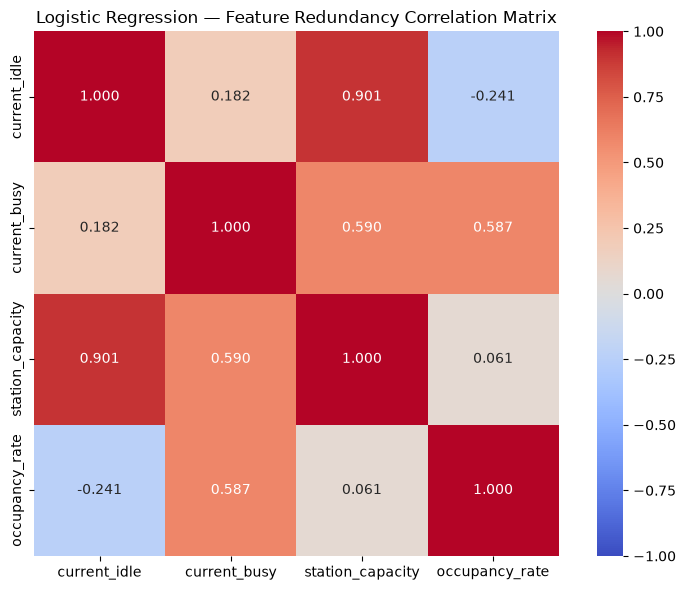

Feature redundancy analysis completed.
Tables and figure exported successfully.


In [90]:

# 5.5 — Feature Redundancy Analysis

redundancy_features = [
    "current_idle",
    "current_busy",
    "station_capacity",
    "occupancy_rate"
]

# Use the approved Model Fit period only
redundancy_df = internal_datasets["Model Fit"][
    redundancy_features
].copy()

# Calculate Pearson correlation
redundancy_corr = redundancy_df.corr(method="pearson")

print("Feature correlation matrix:")
display(redundancy_corr.round(4))

# Check potential deterministic relationships
capacity_difference = (
    redundancy_df["station_capacity"]
    - redundancy_df["current_idle"]
    - redundancy_df["current_busy"]
)

capacity_identity_rate = np.isclose(
    capacity_difference, 0, atol=1e-8
).mean()

# Check whether occupancy_rate equals current_busy / station_capacity
valid_capacity = redundancy_df["station_capacity"] > 0

calculated_occupancy = (
    redundancy_df.loc[valid_capacity, "current_busy"]
    / redundancy_df.loc[valid_capacity, "station_capacity"]
)

occupancy_identity_rate = np.isclose(
    redundancy_df.loc[valid_capacity, "occupancy_rate"],
    calculated_occupancy,
    atol=1e-6
).mean()

relationship_summary = pd.DataFrame({
    "Relationship": [
        "station_capacity = current_idle + current_busy",
        "occupancy_rate = current_busy / station_capacity"
    ],
    "Matching observations (%)": [
        round(capacity_identity_rate * 100, 4),
        round(occupancy_identity_rate * 100, 4)
    ]
})

print("\nPotential deterministic relationships:")
display(relationship_summary)

# Save analysis tables
redundancy_corr.to_csv(
    TABLES_DIR / "logistic_regression_feature_correlations.csv"
)

relationship_summary.to_csv(
    TABLES_DIR / "logistic_regression_feature_relationships.csv",
    index=False
)

# Create correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    redundancy_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)

ax.set_title(
    "Logistic Regression — Feature Redundancy Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "logistic_regression_feature_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature redundancy analysis completed.")
print("Tables and figure exported successfully.")



### Key Findings — Feature Redundancy Analysis

- A strong positive correlation was observed between current idle chargers and station capacity (r = 0.9013).
- Station capacity was exactly equal to the sum of current idle and current busy chargers for 100% of Model Fit observations.
- Occupancy rate was exactly equal to current busy chargers divided by station capacity for 100% of observations with positive capacity.
- These relationships confirm substantial feature redundancy and an exact linear dependency among current idle, current busy, and station capacity.
- Multicollinearity may contribute to coefficient instability and counterintuitive coefficient signs observed in the initial Logistic Regression model.
- The occupancy rate is a derived nonlinear feature that may still provide predictive value.
- Feature removal decisions will be based on controlled comparisons using the approved internal Tuning period rather than correlation alone.



## 5.6. Feature Set Comparison

**Objective:** Evaluate whether removing redundant charger-status features improves Logistic Regression performance or reduces model complexity.

Seven feature configurations are compared, including the full 16-feature set and six reduced alternatives.

All models use L2 regularization, C = 0.01, class_weight = None, the lbfgs solver, and identical convergence settings.

Each candidate is fitted on the approved Model Fit period and evaluated on the separate internal Tuning period.

The primary selection criterion is Class-0 Average Precision (AP₀). Feature count, Class-0 F1, recall, Brier Score, and training time are recorded as secondary information.

The shared validation and test datasets remain excluded from feature selection.


In [91]:

# 5.6 — Feature Set Comparison

feature_sets = {
    "full": list(FEATURE_COLUMNS),
    "no_capacity": [
        f for f in FEATURE_COLUMNS
        if f != "station_capacity"
    ],
    "no_busy": [
        f for f in FEATURE_COLUMNS
        if f != "current_busy"
    ],
    "no_idle": [
        f for f in FEATURE_COLUMNS
        if f != "current_idle"
    ],
    "no_occupancy": [
        f for f in FEATURE_COLUMNS
        if f != "occupancy_rate"
    ],
    "reduced_counts": [
        f for f in FEATURE_COLUMNS
        if f not in ["current_busy", "station_capacity"]
    ],
    "reduced_ratio": [
        f for f in FEATURE_COLUMNS
        if f not in ["occupancy_rate", "station_capacity"]
    ]
}

feature_set_results = []

for set_name, selected_features in feature_sets.items():

    categorical = ["station_id"]
    numerical = [
        f for f in selected_features
        if f != "station_id"
    ]

    # Build a preprocessing transformer for this feature set
    feature_preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=True
                ),
                categorical
            ),
            (
                "numerical",
                StandardScaler(),
                numerical
            )
        ],
        remainder="drop",
        sparse_threshold=1.0
    )

    candidate = Pipeline([
        ("preprocessing", feature_preprocessor),
        ("classifier", LogisticRegression(
            C=0.01,
            l1_ratio=0,
            solver="lbfgs",
            max_iter=2000,
            tol=1e-4,
            class_weight=None,
            random_state=42
        ))
    ])

    # Fit using Model Fit observations only
    start_train = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        candidate.fit(
            X_tune_fit[selected_features],
            y_tune_fit
        )

    train_seconds = time.perf_counter() - start_train

    convergence_warnings = [
        w for w in caught_warnings
        if issubclass(w.category, ConvergenceWarning)
    ]

    # Evaluate on the separate internal Tuning period
    prob_available = candidate.predict_proba(
        X_tune[selected_features]
    )[:, 1]

    pred = (prob_available >= 0.5).astype(int)

    ap_0 = average_precision_score(
        (y_tune.to_numpy() == 0).astype(int),
        1 - prob_available
    )

    feature_set_results.append({
        "feature_set": set_name,
        "n_original_features": len(selected_features),
        "n_encoded_features": candidate.named_steps[
            "classifier"
        ].n_features_in_,
        "ap_0": ap_0,
        "f1_0": f1_score(
            y_tune, pred, pos_label=0, zero_division=0
        ),
        "recall_0": recall_score(
            y_tune, pred, pos_label=0, zero_division=0
        ),
        "brier_score": brier_score_loss(
            y_tune, prob_available
        ),
        "training_seconds": train_seconds,
        "converged": len(convergence_warnings) == 0
    })

    print(
        f"{set_name} | "
        f"Features={len(selected_features)} | "
        f"AP_0={ap_0:.6f} | "
        f"Converged={len(convergence_warnings) == 0}"
    )

lr_feature_set_results_df = pd.DataFrame(
    feature_set_results
).sort_values(
    "ap_0",
    ascending=False
).reset_index(drop=True)

display(lr_feature_set_results_df)

# Export results
lr_feature_set_results_df.to_csv(
    TABLES_DIR / "logistic_regression_feature_set_comparison.csv",
    index=False
)

print("Feature set comparison completed.")
print("Results exported successfully.")


full | Features=16 | AP_0=0.983628 | Converged=True
no_capacity | Features=15 | AP_0=0.983681 | Converged=True
no_busy | Features=15 | AP_0=0.983560 | Converged=True
no_idle | Features=15 | AP_0=0.983617 | Converged=True
no_occupancy | Features=15 | AP_0=0.943163 | Converged=True
reduced_counts | Features=14 | AP_0=0.983783 | Converged=True
reduced_ratio | Features=14 | AP_0=0.943456 | Converged=True


,feature_set,n_original_features,n_encoded_features,ap_0,f1_0,recall_0,brier_score,training_seconds,converged
0,reduced_counts,14,104,0.983783,0.947981,0.912236,0.003086,1.502505,True
1,no_capacity,15,105,0.983681,0.946677,0.907121,0.003181,1.525892,True
2,full,16,106,0.983628,0.946748,0.907121,0.003217,2.121455,True
3,no_idle,15,105,0.983617,0.946677,0.907121,0.003249,1.385641,True
4,no_busy,15,105,0.983560,0.946655,0.906736,0.003306,1.353194,True
5,reduced_ratio,14,104,0.943456,0.913680,0.875856,0.006793,1.653695,True
6,no_occupancy,15,105,0.943163,0.913680,0.875856,0.006846,1.628948,True


Feature set comparison completed.
Results exported successfully.



### Key Findings — Feature Set Comparison

- Seven feature configurations were evaluated using the approved internal Model Fit and Tuning periods.
- The reduced_counts configuration achieved the highest Class-0 Average Precision of 0.983783 with 14 original features.
- Removing current_busy and station_capacity slightly improved AP₀ compared with the full 16-feature configuration (0.983628).
- The reduced_counts configuration also achieved a lower Brier Score (0.003086), higher Class-0 recall (0.912236), and shorter training time.
- Removing occupancy_rate caused a substantial decrease in AP₀, suggesting that this derived feature provides important predictive information for the current model.
- All feature configurations completed training without convergence warnings.
- The preferred configuration for final refitting is L2 regularization, C = 0.01, class_weight = None, and the reduced_counts feature set.
- The selected configuration will be refitted using the complete permitted fitting period before calibration and threshold optimization.
- Shared validation and test observations were not used for feature selection.



## 5.7. Final Estimator Refit

**Objective:** Refit the selected Logistic Regression configuration using the complete permitted fitting period (December 1–29, 2022).

The selected configuration uses L2 regularization, C = 0.01, class_weight = None, and the reduced_counts feature set containing 14 original features.

The Model Fit and Tuning periods are combined only after hyperparameter and feature-set selection is complete.

The Calibration and Threshold periods remain excluded from estimator fitting. They will be used exclusively for probability calibration assessment and classification threshold optimization.

The shared validation and test datasets are not used for estimator fitting.


In [92]:

# 5.7 — Final Estimator Refit

# Use the feature set selected during internal tuning
lr_selected_features = feature_sets["reduced_counts"]

assert len(lr_selected_features) == 14
assert "station_id" in lr_selected_features
assert "prediction_horizon" in lr_selected_features
assert "current_busy" not in lr_selected_features
assert "station_capacity" not in lr_selected_features

# Combine only the approved Model Fit and Tuning periods
final_fit_df = pd.concat(
    [
        internal_datasets["Model Fit"],
        internal_datasets["Tuning"]
    ],
    ignore_index=True
)

X_final_fit = final_fit_df[lr_selected_features]
y_final_fit = final_fit_df["target"].astype(int)

# Verify the permitted training observations
assert len(final_fit_df) == 1_790_062 + 466_897
assert set(y_final_fit.unique()) == {0, 1}
assert final_fit_df["target_time"].max() < pd.Timestamp("2022-12-30")

# Define preprocessing for the selected feature set
lr_selected_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            ["station_id"]
        ),
        (
            "numerical",
            StandardScaler(),
            [
                f for f in lr_selected_features
                if f != "station_id"
            ]
        )
    ],
    remainder="drop",
    sparse_threshold=1.0
)

# Build the selected Logistic Regression pipeline
lr_final_pipeline = Pipeline([
    ("preprocessing", lr_selected_preprocessor),
    ("classifier", LogisticRegression(
        C=0.01,
        l1_ratio=0,
        solver="lbfgs",
        max_iter=2000,
        tol=1e-4,
        class_weight=None,
        random_state=42
    ))
])

# Fit exclusively on December 1–29
start_time = time.perf_counter()

with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    lr_final_pipeline.fit(X_final_fit, y_final_fit)

final_training_seconds = time.perf_counter() - start_time

convergence_warnings = [
    w for w in fit_warnings
    if issubclass(w.category, ConvergenceWarning)
]

assert len(convergence_warnings) == 0
assert set(
    lr_final_pipeline.named_steps["classifier"].classes_
) == {0, 1}

print("Final estimator refit: PASSED")
print("Training observations:", len(X_final_fit))
print("Original features:", len(lr_selected_features))
print(
    "Encoded features:",
    lr_final_pipeline.named_steps["classifier"].n_features_in_
)
print("Training time (seconds):", round(final_training_seconds, 2))
print("Converged without warnings:", len(convergence_warnings) == 0)


Final estimator refit: PASSED
Training observations: 2256959
Original features: 14
Encoded features: 104
Training time (seconds): 2.05
Converged without warnings: True



## 5.8. Probability Calibration Preparation

**Objective:** Prepare the approved internal Calibration dataset and generate uncalibrated probabilities from the selected Logistic Regression estimator.

The calibration period covers December 30, 2022, through January 2, 2023, and is strictly separate from the estimator fitting period.

The fitted estimator remains unchanged. Its availability probabilities will be used to compare the original probability predictions against sigmoid and isotonic calibration methods.

Calibration will only be retained if it provides a justified improvement in probability quality.

The Threshold, Validation, and Test datasets are excluded from calibration fitting.


In [93]:

# 5.8 — Probability Calibration Preparation

# Load the approved internal Calibration period
calibration_df = internal_datasets["Calibration"]

X_cal = calibration_df[lr_selected_features]
y_cal = calibration_df["target"].astype(int)

# Verify dataset boundaries and target values
assert len(calibration_df) == 306_216
assert set(y_cal.unique()) == {0, 1}

assert calibration_df["time"].min() >= pd.Timestamp("2022-12-30")
assert calibration_df["target_time"].max() < pd.Timestamp("2023-01-03")

# Ensure chronological separation from estimator fitting
assert (
    final_fit_df["target_time"].max()
    < calibration_df["time"].min()
)

# Generate uncalibrated probabilities using the fitted estimator
start_time = time.perf_counter()

cal_prob_uncalibrated = lr_final_pipeline.predict_proba(
    X_cal
)[:, 1]

calibration_inference_seconds = time.perf_counter() - start_time

# Validate probability outputs
assert len(cal_prob_uncalibrated) == len(y_cal)
assert np.isfinite(cal_prob_uncalibrated).all()
assert np.all(
    (cal_prob_uncalibrated >= 0)
    & (cal_prob_uncalibrated <= 1)
)

# Compute baseline probability quality
calibration_baseline_brier = brier_score_loss(
    y_cal,
    cal_prob_uncalibrated
)

print("Calibration preparation: PASSED")
print("Calibration observations:", len(X_cal))
print("Original features:", X_cal.shape[1])
print("Unavailable rate:", round(100 * (y_cal == 0).mean(), 2), "%")
print("Uncalibrated Brier Score:", round(calibration_baseline_brier, 6))
print(
    "Inference time (seconds):",
    round(calibration_inference_seconds, 2)
)
print(
    "Probability range:",
    round(cal_prob_uncalibrated.min(), 4),
    "to",
    round(cal_prob_uncalibrated.max(), 4)
)


Calibration preparation: PASSED
Calibration observations: 306216
Original features: 14
Unavailable rate: 3.67 %
Uncalibrated Brier Score: 0.005183
Inference time (seconds): 0.12
Probability range: 0.0047 to 1.0



## 5.9. Sigmoid vs. Isotonic Calibration Comparison

**Objective:** Determine whether post-hoc probability calibration improves the selected Logistic Regression estimator.

The approved Calibration period is divided chronologically:

- Calibration Fit: December 30–31, 2022.
- Calibration Assessment: January 1–2, 2023.

Sigmoid and isotonic calibrators are fitted using the first period and evaluated on the second period. The uncalibrated estimator is included as the baseline.

Brier Score is the primary criterion for calibration selection. Class-0 Average Precision is monitored to detect changes in ranking performance.

The underlying Logistic Regression estimator remains frozen throughout calibration.

No Threshold, Validation, or Test observations are used.


In [94]:

# 5.9.1 — Chronological Calibration Subsets

# Define internal calibration boundaries
cal_fit_start = pd.Timestamp("2022-12-30")
cal_split = pd.Timestamp("2023-01-01")
cal_end = pd.Timestamp("2023-01-03")

# Ensure both observation and target timestamps
# remain within their respective calibration periods
cal_fit_mask = (
    calibration_df["time"].ge(cal_fit_start)
    & calibration_df["time"].lt(cal_split)
    & calibration_df["target_time"].ge(cal_fit_start)
    & calibration_df["target_time"].lt(cal_split)
)

cal_assess_mask = (
    calibration_df["time"].ge(cal_split)
    & calibration_df["time"].lt(cal_end)
    & calibration_df["target_time"].ge(cal_split)
    & calibration_df["target_time"].lt(cal_end)
)

cal_fit_df = calibration_df.loc[cal_fit_mask].copy()
cal_assess_df = calibration_df.loc[cal_assess_mask].copy()

# Prepare features and targets
X_cal_fit = cal_fit_df[lr_selected_features]
y_cal_fit = cal_fit_df["target"].astype(int)

X_cal_assess = cal_assess_df[lr_selected_features]
y_cal_assess = cal_assess_df["target"].astype(int)

# Generate probabilities from the frozen estimator
cal_fit_prob = lr_final_pipeline.predict_proba(X_cal_fit)[:, 1]
cal_assess_prob = lr_final_pipeline.predict_proba(X_cal_assess)[:, 1]

# Validate chronological separation and class coverage
assert not cal_fit_df.empty
assert not cal_assess_df.empty
assert set(y_cal_fit.unique()) == {0, 1}
assert set(y_cal_assess.unique()) == {0, 1}
assert cal_fit_df["target_time"].max() < cal_assess_df["time"].min()

assert np.isfinite(cal_fit_prob).all()
assert np.isfinite(cal_assess_prob).all()
assert np.all((cal_fit_prob >= 0) & (cal_fit_prob <= 1))
assert np.all((cal_assess_prob >= 0) & (cal_assess_prob <= 1))

calibration_split_summary = pd.DataFrame([
    {
        "period": "calibration_fit",
        "observations": len(cal_fit_df),
        "unavailable": int((y_cal_fit == 0).sum()),
        "unavailable_rate (%)": round(100 * (y_cal_fit == 0).mean(), 2),
    },
    {
        "period": "calibration_assessment",
        "observations": len(cal_assess_df),
        "unavailable": int((y_cal_assess == 0).sum()),
        "unavailable_rate (%)": round(100 * (y_cal_assess == 0).mean(), 2),
    }
])

display(calibration_split_summary)

# Save the calibration split summary
calibration_split_summary.to_csv(
    TABLES_DIR / "logistic_regression_calibration_split_summary.csv",
    index=False
)

print("Chronological calibration subsets: PASSED")
print("Calibration split summary exported successfully.")


,period,observations,unavailable,unavailable_rate (%)
0,calibration_fit,152424,5910,3.88
1,calibration_assessment,151478,5241,3.46


Chronological calibration subsets: PASSED
Calibration split summary exported successfully.


In [95]:

# 5.9.2 — Sigmoid vs. Isotonic Calibration

from sklearn.linear_model import LogisticRegression as CalibrationLogisticRegression
from sklearn.isotonic import IsotonicRegression

# 1. Uncalibrated baseline
baseline_assess_prob = cal_assess_prob

# 2. Sigmoid calibration (Platt scaling)
sigmoid_calibrator = CalibrationLogisticRegression(
    C=1e6,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

sigmoid_calibrator.fit(
    cal_fit_prob.reshape(-1, 1),
    y_cal_fit
)

sigmoid_assess_prob = sigmoid_calibrator.predict_proba(
    cal_assess_prob.reshape(-1, 1)
)[:, 1]

# 3. Isotonic calibration
isotonic_calibrator = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip"
)

isotonic_calibrator.fit(
    cal_fit_prob,
    y_cal_fit
)

isotonic_assess_prob = isotonic_calibrator.predict(
    cal_assess_prob
)

# Compare calibration methods on held-out assessment data
calibration_comparison = []

for method_name, probabilities in [
    ("uncalibrated", baseline_assess_prob),
    ("sigmoid", sigmoid_assess_prob),
    ("isotonic", isotonic_assess_prob)
]:
    assert np.isfinite(probabilities).all()
    assert np.all((probabilities >= 0) & (probabilities <= 1))

    calibration_comparison.append({
        "method": method_name,
        "brier_score": brier_score_loss(
            y_cal_assess, probabilities
        ),
        "ap_0": average_precision_score(
            (y_cal_assess.to_numpy() == 0).astype(int),
            1 - probabilities
        )
    })

lr_calibration_comparison_df = pd.DataFrame(
    calibration_comparison
).sort_values(
    "brier_score",
    ascending=True
).reset_index(drop=True)

display(lr_calibration_comparison_df)

# Export the comparison
lr_calibration_comparison_df.to_csv(
    TABLES_DIR / "logistic_regression_calibration_comparison.csv",
    index=False
)

print("Calibration method comparison: PASSED")
print("Comparison results exported successfully.")


,method,brier_score,ap_0
0,isotonic,0.002794,0.985892
1,uncalibrated,0.004762,0.987683
2,sigmoid,0.006574,0.987683


Calibration method comparison: PASSED
Comparison results exported successfully.



### 5.9.3. Selected Calibration Method

Isotonic regression was selected based on its superior Brier Score on the held-out Calibration Assessment period.

- Uncalibrated Brier Score: 0.004762
- Isotonic Brier Score: 0.002794
- Relative Brier Score reduction: approximately 41.3%
- Uncalibrated Class-0 AP: 0.987683
- Isotonic Class-0 AP: 0.985892

The improved probability quality comes with a small reduction in ranking performance.

Sigmoid calibration was not selected because it increased the Brier Score without improving Class-0 Average Precision.

Following method selection, the isotonic calibrator is refitted using the complete approved Calibration period. The underlying Logistic Regression estimator remains frozen.

No Threshold, Validation, or Test observations are used for calibration fitting or selection.


In [96]:

# 5.9.3 — Refit the Selected Isotonic Calibrator

# Fit isotonic regression on the complete approved Calibration period
lr_final_calibrator = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip"
)

lr_final_calibrator.fit(
    cal_prob_uncalibrated,
    y_cal
)

# Verify the fitted calibrator on calibration data
cal_prob_isotonic = lr_final_calibrator.predict(
    cal_prob_uncalibrated
)

assert len(cal_prob_isotonic) == len(y_cal)
assert np.isfinite(cal_prob_isotonic).all()
assert np.all(
    (cal_prob_isotonic >= 0)
    & (cal_prob_isotonic <= 1)
)

# Record calibration metadata
lr_selected_calibration_method = "isotonic"

print("Selected calibration method:", lr_selected_calibration_method)
print("Calibration fit observations:", len(y_cal))
print("Underlying estimator unchanged:", True)
print("Final isotonic calibrator fitted successfully.")


Selected calibration method: isotonic
Calibration fit observations: 306216
Underlying estimator unchanged: True
Final isotonic calibrator fitted successfully.



## 5.10. Classification Threshold Optimization

**Objective:** Select the classification threshold that maximizes Class-0 F1-score on the approved internal Threshold period.

The optimized Logistic Regression estimator and isotonic calibrator are already fitted and remain frozen.

The threshold optimization period covers January 3–5, 2023.

Since the model predicts P(Available = 1), binary predictions are generated using:

- Class 1 (Available) if probability >= threshold.
- Class 0 (Unavailable) if probability < threshold.

Threshold selection is performed exclusively on the internal Threshold dataset.

No shared validation or test observations are used.

### 5.10.1. Threshold Dataset Preparation

Generate calibrated availability probabilities using the frozen Logistic Regression estimator and selected isotonic calibrator.


In [97]:

# 5.10.1 — Threshold Dataset Preparation

# Load the approved internal Threshold period
threshold_df = internal_datasets["Threshold"]

X_threshold = threshold_df[lr_selected_features]
y_threshold = threshold_df["target"].astype(int)

# Verify dataset size and target distribution
assert len(threshold_df) == 228_374
assert set(y_threshold.unique()) == {0, 1}

# Verify chronological boundaries
assert threshold_df["time"].min() >= pd.Timestamp("2023-01-03")
assert threshold_df["target_time"].max() < pd.Timestamp("2023-01-06")

# Ensure separation from the Calibration period
assert (
    calibration_df["target_time"].max()
    < threshold_df["time"].min()
)

# Generate probabilities using the frozen estimator
threshold_prob_uncalibrated = lr_final_pipeline.predict_proba(
    X_threshold
)[:, 1]

# Apply the selected isotonic calibrator
threshold_prob_calibrated = lr_final_calibrator.predict(
    threshold_prob_uncalibrated
)

# Validate probabilities
assert len(threshold_prob_calibrated) == len(y_threshold)
assert np.isfinite(threshold_prob_calibrated).all()
assert np.all(
    (threshold_prob_calibrated >= 0)
    & (threshold_prob_calibrated <= 1)
)

# Evaluate the default threshold as a reference
threshold_pred_default = (
    threshold_prob_calibrated >= 0.5
).astype(int)

threshold_default_f1_0 = f1_score(
    y_threshold,
    threshold_pred_default,
    pos_label=0,
    zero_division=0
)

threshold_default_recall_0 = recall_score(
    y_threshold,
    threshold_pred_default,
    pos_label=0,
    zero_division=0
)

print("Threshold dataset preparation: PASSED")
print("Threshold observations:", len(X_threshold))
print("Unavailable observations:", int((y_threshold == 0).sum()))
print("Unavailable rate:", round(100 * (y_threshold == 0).mean(), 2), "%")
print("Default threshold:", 0.5)
print("Default Class-0 F1:", round(threshold_default_f1_0, 6))
print("Default Class-0 Recall:", round(threshold_default_recall_0, 6))
print(
    "Calibrated probability range:",
    round(threshold_prob_calibrated.min(), 4),
    "to",
    round(threshold_prob_calibrated.max(), 4)
)


Threshold dataset preparation: PASSED
Threshold observations: 228374
Unavailable observations: 8610
Unavailable rate: 3.77 %
Default threshold: 0.5
Default Class-0 F1: 0.919116
Default Class-0 Recall: 0.908014
Calibrated probability range: 0.0 to 1.0


In [98]:

# 5.10.2 — Classification Threshold Search

# Evaluate thresholds from 0.05 to 0.95
threshold_candidates = np.round(
    np.arange(0.05, 0.951, 0.01),
    2
)

threshold_search_results = []

for threshold_value in threshold_candidates:

    # Predict availability using the candidate threshold
    candidate_predictions = (
        threshold_prob_calibrated >= threshold_value
    ).astype(int)

    # Calculate Class-0 classification metrics
    candidate_f1 = f1_score(
        y_threshold,
        candidate_predictions,
        pos_label=0,
        zero_division=0
    )

    candidate_precision = precision_score(
        y_threshold,
        candidate_predictions,
        pos_label=0,
        zero_division=0
    )

    candidate_recall = recall_score(
        y_threshold,
        candidate_predictions,
        pos_label=0,
        zero_division=0
    )

    threshold_search_results.append({
        "threshold": threshold_value,
        "f1_0": candidate_f1,
        "precision_0": candidate_precision,
        "recall_0": candidate_recall,
        "predicted_unavailable": int(
            (candidate_predictions == 0).sum()
        )
    })

# Create and rank threshold comparison table
lr_threshold_results_df = pd.DataFrame(
    threshold_search_results
)

lr_threshold_ranked_df = lr_threshold_results_df.sort_values(
    ["f1_0", "threshold"],
    ascending=[False, True]
).reset_index(drop=True)

# Select the threshold with the highest Class-0 F1
lr_optimized_threshold = float(
    lr_threshold_ranked_df.iloc[0]["threshold"]
)

# Display the best candidates
print("Top 10 thresholds by Class-0 F1:")
display(lr_threshold_ranked_df.head(10))

print("\nSelected optimized threshold:", lr_optimized_threshold)
print(
    "Best Class-0 F1:",
    round(lr_threshold_ranked_df.iloc[0]["f1_0"], 6)
)
print(
    "Default Class-0 F1:",
    round(threshold_default_f1_0, 6)
)

# Export the complete threshold comparison
lr_threshold_results_df.to_csv(
    TABLES_DIR / "logistic_regression_threshold_search.csv",
    index=False
)

print("Threshold optimization: PASSED")
print("Threshold search results exported successfully.")


Top 10 thresholds by Class-0 F1:


,threshold,f1_0,precision_0,recall_0,predicted_unavailable
0,0.16,0.919116,0.930493,0.908014,8402
1,0.17,0.919116,0.930493,0.908014,8402
2,0.18,0.919116,0.930493,0.908014,8402
3,0.19,0.919116,0.930493,0.908014,8402
4,0.20,0.919116,0.930493,0.908014,8402
5,0.21,0.919116,0.930493,0.908014,8402
6,0.22,0.919116,0.930493,0.908014,8402
7,0.23,0.919116,0.930493,0.908014,8402
8,0.24,0.919116,0.930493,0.908014,8402
9,0.25,0.919116,0.930493,0.908014,8402



Selected optimized threshold: 0.16
Best Class-0 F1: 0.919116
Default Class-0 F1: 0.919116
Threshold optimization: PASSED
Threshold search results exported successfully.


In [99]:

# 5.10.3 — Threshold Selection and Verification

# Identify thresholds with the maximum Class-0 F1
best_f1 = lr_threshold_results_df["f1_0"].max()

best_thresholds = lr_threshold_results_df.loc[
    np.isclose(
        lr_threshold_results_df["f1_0"],
        best_f1,
        rtol=0,
        atol=1e-12
    ),
    "threshold"
].to_numpy()

# Prefer the default threshold when it achieves maximum F1
if np.any(np.isclose(best_thresholds, 0.5)):
    lr_optimized_threshold = 0.5
    threshold_selection_reason = (
        "The default threshold achieves the maximum internal "
        "Class-0 F1; no threshold adjustment is required."
    )
else:
    lr_optimized_threshold = float(
        best_thresholds[
            np.argmin(np.abs(best_thresholds - 0.5))
        ]
    )
    threshold_selection_reason = (
        "Selected the F1-maximizing threshold closest to 0.5."
    )

# Verify selected threshold performance
selected_threshold_predictions = (
    threshold_prob_calibrated >= lr_optimized_threshold
).astype(int)

selected_threshold_f1 = f1_score(
    y_threshold,
    selected_threshold_predictions,
    pos_label=0,
    zero_division=0
)

assert np.isclose(selected_threshold_f1, best_f1)

# Save threshold decision
lr_threshold_selection_df = pd.DataFrame([{
    "selected_threshold": lr_optimized_threshold,
    "best_internal_f1_0": selected_threshold_f1,
    "default_threshold_f1_0": threshold_default_f1_0,
    "number_of_tied_thresholds": len(best_thresholds),
    "selection_reason": threshold_selection_reason
}])

lr_threshold_selection_df.to_csv(
    TABLES_DIR / "logistic_regression_threshold_selection.csv",
    index=False
)

print("Selected threshold:", lr_optimized_threshold)
print("Maximum Class-0 F1:", round(selected_threshold_f1, 6))
print("Number of tied thresholds:", len(best_thresholds))
print("Selection reason:", threshold_selection_reason)
print("Threshold selection: PASSED")


Selected threshold: 0.5
Maximum Class-0 F1: 0.919116
Number of tied thresholds: 55
Selection reason: The default threshold achieves the maximum internal Class-0 F1; no threshold adjustment is required.
Threshold selection: PASSED



### Key Findings — Threshold Optimization

- Classification thresholds from 0.05 to 0.95 were evaluated using the approved internal Threshold period.
- The maximum Class-0 F1-score was 0.919116.
- A total of 55 candidate thresholds achieved the same maximum F1-score.
- The default threshold of 0.50 was among the F1-maximizing thresholds.
- The threshold was therefore retained at 0.50 to avoid an unnecessary adjustment.
- The final estimator, isotonic calibrator, and classification threshold are now frozen.
- No shared validation or test observations were used for threshold selection.



## 5.11. Optimized Validation Predictions

**Objective:** Generate predictions from the frozen optimized Logistic Regression model on the complete shared validation dataset.

The optimized model consists of:

- A 14-feature Logistic Regression estimator trained on December 1–29, 2022.
- An isotonic probability calibrator fitted on December 30, 2022 – January 2, 2023.
- A fixed classification threshold of 0.50 selected using January 3–5, 2023.

The output follows the shared VoltAhead prediction schema and includes all validation observations, including unseen station 1948.

The validation dataset is used strictly for final evaluation and is not used to modify the selected model.


In [100]:

# 5.11 — Optimized Validation Predictions

# Prepare the selected 14 input features
X_val_optimized = validation_df[lr_selected_features]

# Generate probabilities using the frozen estimator and calibrator
start_time = time.perf_counter()

optimized_val_prob_uncalibrated = (
    lr_final_pipeline.predict_proba(X_val_optimized)[:, 1]
)

optimized_val_prob = lr_final_calibrator.predict(
    optimized_val_prob_uncalibrated
)

optimized_inference_seconds = time.perf_counter() - start_time

# Apply the selected classification threshold
optimized_val_pred = (
    optimized_val_prob >= lr_optimized_threshold
).astype(int)

# Build the shared prediction output
lr_optimized_predictions = validation_df[
    ["station_id", "time", "target_time", "prediction_horizon"]
].copy()

lr_optimized_predictions["y_true"] = y_val.to_numpy()
lr_optimized_predictions["y_pred"] = optimized_val_pred
lr_optimized_predictions["y_prob"] = optimized_val_prob
lr_optimized_predictions["model_name"] = "logistic_regression"
lr_optimized_predictions["model_version"] = "optimized"
lr_optimized_predictions["threshold"] = lr_optimized_threshold

lr_optimized_predictions = lr_optimized_predictions[
    prediction_columns
]

# Validate the output
assert len(lr_optimized_predictions) == 618_726
assert not lr_optimized_predictions.isna().any().any()
assert lr_optimized_predictions["y_prob"].between(0, 1).all()
assert not lr_optimized_predictions.duplicated(
    ["station_id", "time", "prediction_horizon"]
).any()

assert (
    lr_optimized_predictions["y_pred"].to_numpy()
    == (lr_optimized_predictions["y_prob"] >= lr_optimized_threshold)
       .astype(int).to_numpy()
).all()

# Confirm that the unseen station was preserved
assert (
    lr_optimized_predictions.loc[
        ~lr_optimized_predictions["station_id"].isin(training_station_ids),
        "station_id"
    ].unique().tolist()
) == [1948]

print("Optimized validation predictions: PASSED")
print("Validation observations:", len(lr_optimized_predictions))
print("Original features:", len(lr_selected_features))
print("Selected threshold:", lr_optimized_threshold)
print("Inference time (seconds):", round(optimized_inference_seconds, 2))
print("Predicted available:", int((optimized_val_pred == 1).sum()))
print("Predicted unavailable:", int((optimized_val_pred == 0).sum()))
print(
    "Probability range:",
    round(optimized_val_prob.min(), 4),
    "to",
    round(optimized_val_prob.max(), 4)
)

display(lr_optimized_predictions.head())


Optimized validation predictions: PASSED
Validation observations: 618726
Original features: 14
Selected threshold: 0.5
Inference time (seconds): 0.15
Predicted available: 591895
Predicted unavailable: 26831
Probability range: 0.0 to 1.0


,station_id,time,target_time,prediction_horizon,y_true,y_pred,y_prob,model_name,model_version,threshold
0,1703,2023-01-06,2023-01-06 00:30:00,30,1,1,0.997448,logistic_regression,optimized,0.5
1,1703,2023-01-06,2023-01-06 00:40:00,40,1,1,0.997448,logistic_regression,optimized,0.5
2,1703,2023-01-06,2023-01-06 01:00:00,60,1,1,0.997448,logistic_regression,optimized,0.5
3,1712,2023-01-06,2023-01-06 00:30:00,30,1,1,0.995260,logistic_regression,optimized,0.5
4,1712,2023-01-06,2023-01-06 00:40:00,40,1,1,0.995260,logistic_regression,optimized,0.5



## 5.12. Optimized Logistic Regression Evaluation

**Objective:** Evaluate the frozen optimized Logistic Regression model on the complete shared validation dataset using the common VoltAhead evaluation module.

The optimized model uses 14 selected input features, L2 regularization with C = 0.01, isotonic probability calibration, and a fixed classification threshold of 0.50.

The evaluation includes overall performance, prediction-horizon comparisons, and seen/unseen station analysis.

The primary comparison metric is seen-station Class-0 Average Precision (AP₀).

All optimization decisions were completed using the approved internal chronological training periods before this validation evaluation.


In [101]:

# 5.12 — Optimized Logistic Regression Evaluation

# Evaluate with the same shared module used for the initial model
lr_optimized_evaluation = export_evaluation_results(
    lr_optimized_predictions,
    training_station_ids,
    reference=validation_df
)

# Retrieve standardized evaluation tables
lr_optimized_overall = lr_optimized_evaluation["overall"]
lr_optimized_by_horizon = lr_optimized_evaluation["by_horizon"]
lr_optimized_by_station_group = lr_optimized_evaluation[
    "by_station_group"
]

print("=== Optimized Overall Validation Performance ===")
display(lr_optimized_overall)

print("=== Optimized Performance by Prediction Horizon ===")
display(lr_optimized_by_horizon)

print("=== Optimized Seen vs. Unseen Station Performance ===")
display(lr_optimized_by_station_group)

print("Optimized Logistic Regression evaluation: PASSED")


Saved: outputs/tables/logistic_regression_optimized_overall.csv
Saved: outputs/tables/logistic_regression_optimized_by_horizon.csv
Saved: outputs/tables/logistic_regression_optimized_by_station_group.csv
=== Optimized Overall Validation Performance ===


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,logistic_regression,optimized,overall,90,618726,0.995161,0.978728,0.926205,0.960796,0.943184,0.98988,0.953411,0.00452,24851,1014,1980,590881


=== Optimized Performance by Prediction Horizon ===


,model_name,model_version,evaluation_group,prediction_horizon,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,logistic_regression,optimized,horizon,30,90,206482,0.995777,0.982402,0.933639,0.967805,0.950415,0.991612,0.960657,0.003995,8357,278,594,197253
1,logistic_regression,optimized,horizon,40,90,206302,0.995293,0.979525,0.927789,0.962319,0.944738,0.990347,0.954999,0.004411,8300,325,646,197031
2,logistic_regression,optimized,horizon,60,90,205942,0.994411,0.974244,0.917170,0.952237,0.934375,0.987675,0.944667,0.005157,8194,411,740,196597


=== Optimized Seen vs. Unseen Station Performance ===


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,logistic_regression,optimized,seen,89,612854,0.995134,0.978935,0.926205,0.961242,0.943398,0.990250,0.953836,0.004544,24851,1002,1980,585021
1,logistic_regression,optimized,unseen,1,5872,0.997956,0.500000,NaN,0.000000,0.000000,0.422355,0.002044,0.002088,0,12,0,5860


Optimized Logistic Regression evaluation: PASSED



## 5.13. Initial vs. Optimized Model Comparison

**Objective:** Compare the initial and optimized Logistic Regression models using the standardized shared validation metrics.

The optimized model improves Class-0 recall, Class-0 F1, balanced accuracy, and Brier Score, but produces lower Class-0 Average Precision.

The primary project comparison metric is seen-station Class-0 Average Precision. Therefore, the initial model remains preferable under the predefined primary criterion.

Both model versions are retained and reported. Validation results are not used to retune hyperparameters, calibration, feature selection, or classification thresholds.


In [102]:

# 5.13 — Initial vs. Optimized Model Comparison

comparison_metrics = [
    "accuracy",
    "balanced_accuracy",
    "precision_0",
    "recall_0",
    "f1_0",
    "roc_auc",
    "ap_0",
    "brier_score"
]

# Compare overall validation metrics
initial_metrics = lr_initial_overall.iloc[0]
optimized_metrics = lr_optimized_overall.iloc[0]

lr_model_comparison_df = pd.DataFrame({
    "metric": comparison_metrics,
    "initial": [
        initial_metrics[m] for m in comparison_metrics
    ],
    "optimized": [
        optimized_metrics[m] for m in comparison_metrics
    ]
})

lr_model_comparison_df["difference"] = (
    lr_model_comparison_df["optimized"]
    - lr_model_comparison_df["initial"]
)

# Extract seen-station AP_0 separately
initial_seen_ap = lr_initial_by_station_group.loc[
    lr_initial_by_station_group["evaluation_group"] == "seen",
    "ap_0"
].iloc[0]

optimized_seen_ap = lr_optimized_by_station_group.loc[
    lr_optimized_by_station_group["evaluation_group"] == "seen",
    "ap_0"
].iloc[0]

seen_ap_row = pd.DataFrame([{
    "metric": "seen_station_ap_0",
    "initial": initial_seen_ap,
    "optimized": optimized_seen_ap,
    "difference": optimized_seen_ap - initial_seen_ap
}])

lr_model_comparison_df = pd.concat(
    [lr_model_comparison_df, seen_ap_row],
    ignore_index=True
)

display(lr_model_comparison_df.round(6))

# Export the comparison table
lr_model_comparison_df.to_csv(
    TABLES_DIR / "logistic_regression_initial_vs_optimized.csv",
    index=False
)

print("Primary metric: seen-station AP_0")
print("Initial:", round(initial_seen_ap, 6))
print("Optimized:", round(optimized_seen_ap, 6))

print(
    "Preferred by primary metric:",
    "initial" if initial_seen_ap >= optimized_seen_ap else "optimized"
)

print("Model comparison exported successfully.")


,metric,initial,optimized,difference
0,accuracy,0.993732,0.995161,0.001429
1,balanced_accuracy,0.935812,0.978728,0.042916
2,precision_0,0.974820,0.926205,-0.048615
3,recall_0,0.872608,0.960796,0.088189
4,f1_0,0.920886,0.943184,0.022297
5,roc_auc,0.991961,0.989880,-0.002081
6,ap_0,0.966940,0.953411,-0.013529
7,brier_score,0.005097,0.004520,-0.000577
8,seen_station_ap_0,0.967384,0.953836,-0.013548


Primary metric: seen-station AP_0
Initial: 0.967384
Optimized: 0.953836
Preferred by primary metric: initial
Model comparison exported successfully.



## 5.14. Initial vs. Optimized Performance Visualization

**Objective:** Visualize the differences between initial and optimized Logistic Regression performance on the shared validation dataset.

The comparison focuses on Class-0 Average Precision, precision, recall, F1-score, and the primary seen-station Average Precision metric.

The optimized model improves Class-0 recall and F1-score but reduces ranking performance measured by Average Precision.

Both model versions are retained. The initial model is preferred under the predefined primary selection criterion.


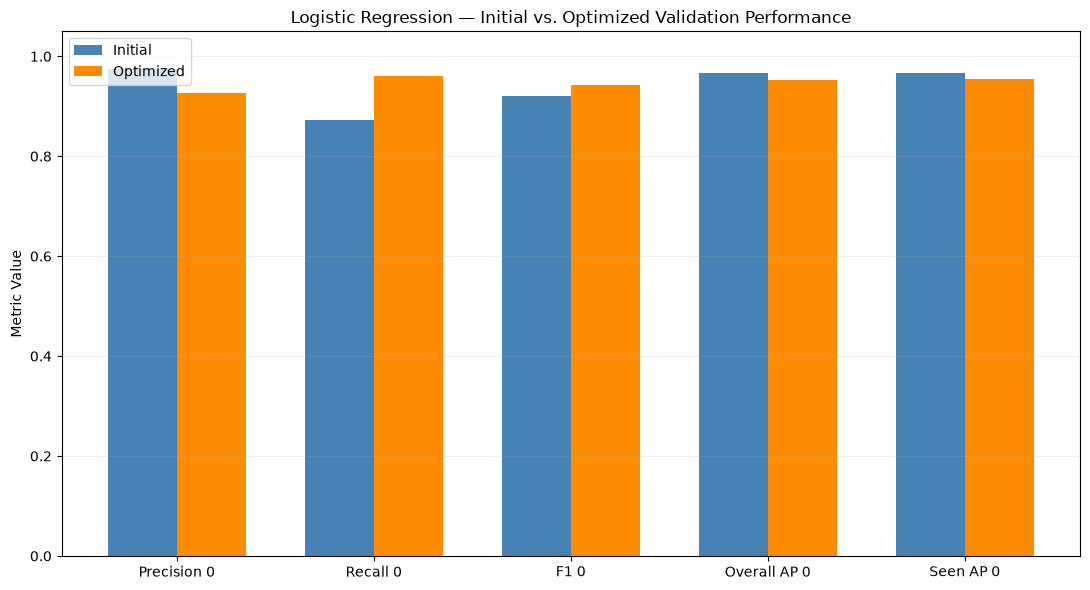

Initial vs. optimized visualization: PASSED
Comparison figure exported successfully.


In [103]:

# 5.14 — Initial vs. Optimized Performance Visualization

# Select metrics for the comparison chart
plot_metrics = [
    "precision_0",
    "recall_0",
    "f1_0",
    "ap_0",
    "seen_station_ap_0"
]

plot_comparison = lr_model_comparison_df.loc[
    lr_model_comparison_df["metric"].isin(plot_metrics)
].copy()

x = np.arange(len(plot_comparison))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - bar_width / 2,
    plot_comparison["initial"],
    bar_width,
    label="Initial",
    color="steelblue"
)

ax.bar(
    x + bar_width / 2,
    plot_comparison["optimized"],
    bar_width,
    label="Optimized",
    color="darkorange"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Precision 0",
        "Recall 0",
        "F1 0",
        "Overall AP 0",
        "Seen AP 0"
    ]
)

ax.set_ylabel("Metric Value")
ax.set_ylim(0, 1.05)
ax.set_title(
    "Logistic Regression — Initial vs. Optimized Validation Performance"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Export visualization
plt.savefig(
    FIGURES_DIR / "logistic_regression_initial_vs_optimized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Initial vs. optimized visualization: PASSED")
print("Comparison figure exported successfully.")



## 5.15. Optimization Findings & Conclusion

### Optimization Summary

The Logistic Regression model was optimized using the approved internal chronological training splits. Hyperparameter tuning, feature selection, probability calibration, and threshold optimization were completed without using the shared validation or test datasets for model selection.

### Selected Optimized Configuration

| Component | Configuration |
|---|---|
| Model | Logistic Regression |
| Regularization | L2 |
| C | 0.01 |
| Solver | lbfgs |
| Class weighting | None |
| Input features | 14 (reduced_counts) |
| Removed features | current_busy, station_capacity |
| Probability calibration | Isotonic |
| Classification threshold | 0.50 |
| Random seed | 42 |

The final estimator was fitted on 2,256,959 observations from December 1–29, 2022. The isotonic calibrator was fitted on the separate December 30, 2022 – January 2, 2023 Calibration period.

### Optimization Findings

**1. Hyperparameter Tuning**

Stronger L2 regularization improved internal Tuning Class-0 Average Precision. The preferred configuration used C = 0.01 with no class weighting.

**2. Regularization Comparison**

L2 achieved the highest internal Tuning AP₀ (0.983628) and substantially shorter training times than L1 and Elastic Net.

**3. Feature Selection**

The reduced_counts feature set achieved the highest internal Tuning AP₀ (0.983783). Removing current_busy and station_capacity reduced feature redundancy while preserving predictive performance.

**4. Probability Calibration**

Isotonic calibration improved held-out calibration Brier Score from 0.004762 to 0.002794, but reduced Class-0 AP from 0.987683 to 0.985892.

**5. Threshold Optimization**

The default threshold of 0.50 achieved the maximum internal Class-0 F1-score of 0.919116. Since 55 candidate thresholds achieved the same maximum score, the default threshold was retained.

### Validation Performance Comparison

| Metric | Initial | Optimized |
|---|---:|---:|
| Accuracy | 0.993732 | 0.995161 |
| Balanced Accuracy | 0.935812 | 0.978728 |
| Class-0 Precision | 0.974820 | 0.926205 |
| Class-0 Recall | 0.872608 | 0.960796 |
| Class-0 F1 | 0.920886 | 0.943184 |
| Overall Class-0 AP | 0.966940 | 0.953411 |
| Seen-station Class-0 AP | 0.967384 | 0.953836 |
| Brier Score | 0.005097 | 0.004520 |

### Final Findings

- Optimization improved Class-0 recall, F1-score, balanced accuracy, and Brier Score.
- Missed unavailable observations decreased from 3,295 to 1,014.
- False unavailable predictions increased from 583 to 1,980.
- The optimized model produced lower Class-0 Average Precision than the initial model.
- Neither model successfully detected the 12 unavailable observations at unseen station 1948.
- The initial model achieved the highest seen-station AP₀ (0.967384) and is therefore preferred under the project's predefined primary comparison metric.
- Both initial and optimized versions will be preserved for reproducibility and team-level evaluation.

### Conclusion

The optimized Logistic Regression model demonstrates a trade-off between unavailable-state detection and probability ranking performance.

Although optimization improved threshold-dependent classification metrics and probability quality, it did not improve the primary model selection metric.

Accordingly, the initial Logistic Regression model is the preferred version for the team's primary AP₀-based comparison, while the optimized version provides an alternative with higher Class-0 recall.

No further hyperparameter or calibration changes will be made based on shared validation results. The test dataset remains untouched.



# Step 6 — Model Artifacts and Reproducibility

## 6.1. Model Artifacts and Prediction Export

**Objective:** Save the fitted initial and optimized Logistic Regression models, including their preprocessing transformations and calibration components, together with the complete validation prediction outputs.

The initial model artifact contains the fitted 16-feature preprocessing and Logistic Regression pipeline.

The optimized model artifact contains the fitted 14-feature preprocessing and Logistic Regression pipeline, the selected isotonic calibrator, and the fixed classification threshold.

Validation predictions for both versions are exported in the shared VoltAhead schema.

Large model and prediction artifacts are stored locally and excluded from Git version control. Reproducibility metadata and small evaluation outputs will be tracked separately.


In [104]:

# 6.1 — Model Artifacts and Prediction Export

import joblib

# Prepare artifact directories
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"
PREDICTIONS_DIR = PROJECT_ROOT / "outputs" / "predictions"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

# Define model artifact paths
initial_model_path = (
    MODELS_DIR / "logistic_regression_initial.joblib"
)

optimized_model_path = (
    MODELS_DIR / "logistic_regression_optimized.joblib"
)

# Save the initial model and its fitted preprocessing
initial_artifact = {
    "model_name": "logistic_regression",
    "model_version": "initial",
    "pipeline": lr_initial_pipeline,
    "feature_columns": list(FEATURE_COLUMNS),
    "threshold": initial_threshold,
    "calibration_method": "none",
}

joblib.dump(initial_artifact, initial_model_path)

# Save the optimized model and calibration components
optimized_artifact = {
    "model_name": "logistic_regression",
    "model_version": "optimized",
    "pipeline": lr_final_pipeline,
    "feature_columns": list(lr_selected_features),
    "calibrator": lr_final_calibrator,
    "calibration_method": lr_selected_calibration_method,
    "threshold": lr_optimized_threshold,
}

joblib.dump(optimized_artifact, optimized_model_path)

# Export shared validation predictions
initial_predictions_path = (
    PREDICTIONS_DIR / "logistic_regression_initial_validation.parquet"
)

optimized_predictions_path = (
    PREDICTIONS_DIR / "logistic_regression_optimized_validation.parquet"
)

lr_initial_predictions.to_parquet(
    initial_predictions_path,
    index=False
)

lr_optimized_predictions.to_parquet(
    optimized_predictions_path,
    index=False
)

# Verify files exist and contain data
artifact_paths = [
    initial_model_path,
    optimized_model_path,
    initial_predictions_path,
    optimized_predictions_path,
]

assert all(path.is_file() for path in artifact_paths)
assert all(path.stat().st_size > 0 for path in artifact_paths)

print("Model and prediction artifact export: PASSED")

for path in artifact_paths:
    print(
        f"{path.relative_to(PROJECT_ROOT)} "
        f"({path.stat().st_size / (1024 ** 2):.2f} MB)"
    )


Model and prediction artifact export: PASSED
outputs/models/logistic_regression_initial.joblib (0.01 MB)
outputs/models/logistic_regression_optimized.joblib (0.01 MB)
outputs/predictions/logistic_regression_initial_validation.parquet (1.97 MB)
outputs/predictions/logistic_regression_optimized_validation.parquet (0.27 MB)



## 6.2. Model Reload and Prediction Consistency Test

**Objective:** Verify that the saved initial and optimized Logistic Regression artifacts can be reloaded and reproduce the original validation predictions.

The test confirms:

- Successful deserialization of both fitted pipelines.
- Preservation of the fitted One-Hot Encoder and StandardScaler.
- Preservation of the optimized isotonic calibrator and classification threshold.
- Numerical consistency between original and reloaded availability probabilities.
- Exact agreement of the binary predictions.
- Consistency of the saved validation Parquet files.

Model artifacts are loaded only from trusted, locally generated files.


In [105]:

# 6.2 — Model Reload and Prediction Consistency Test

# Reload locally saved model artifacts
reloaded_initial = joblib.load(initial_model_path)
reloaded_optimized = joblib.load(optimized_model_path)

# Reproduce initial model predictions
reloaded_initial_prob = reloaded_initial[
    "pipeline"
].predict_proba(
    validation_df[reloaded_initial["feature_columns"]]
)[:, 1]

reloaded_initial_pred = (
    reloaded_initial_prob >= reloaded_initial["threshold"]
).astype(int)

# Reproduce optimized model predictions
reloaded_optimized_raw_prob = reloaded_optimized[
    "pipeline"
].predict_proba(
    validation_df[reloaded_optimized["feature_columns"]]
)[:, 1]

reloaded_optimized_prob = reloaded_optimized[
    "calibrator"
].predict(reloaded_optimized_raw_prob)

reloaded_optimized_pred = (
    reloaded_optimized_prob >= reloaded_optimized["threshold"]
).astype(int)

# Verify probability consistency
np.testing.assert_allclose(
    reloaded_initial_prob,
    lr_initial_predictions["y_prob"].to_numpy(),
    rtol=0,
    atol=1e-12
)

np.testing.assert_allclose(
    reloaded_optimized_prob,
    lr_optimized_predictions["y_prob"].to_numpy(),
    rtol=0,
    atol=1e-12
)

# Verify exact binary prediction agreement
np.testing.assert_array_equal(
    reloaded_initial_pred,
    lr_initial_predictions["y_pred"].to_numpy()
)

np.testing.assert_array_equal(
    reloaded_optimized_pred,
    lr_optimized_predictions["y_pred"].to_numpy()
)

# Reload saved validation prediction files
saved_initial_predictions = pd.read_parquet(
    initial_predictions_path
)

saved_optimized_predictions = pd.read_parquet(
    optimized_predictions_path
)

# Verify exact prediction DataFrame consistency
pd.testing.assert_frame_equal(
    saved_initial_predictions,
    lr_initial_predictions,
    check_exact=True
)

pd.testing.assert_frame_equal(
    saved_optimized_predictions,
    lr_optimized_predictions,
    check_exact=True
)

print("Initial model reload: PASSED")
print("Optimized model reload: PASSED")
print("Initial probability consistency: PASSED")
print("Optimized probability consistency: PASSED")
print("Binary prediction consistency: PASSED")
print("Saved prediction files consistency: PASSED")
print("Model reproducibility test: PASSED")


Initial model reload: PASSED
Optimized model reload: PASSED
Initial probability consistency: PASSED
Optimized probability consistency: PASSED
Binary prediction consistency: PASSED
Saved prediction files consistency: PASSED
Model reproducibility test: PASSED



## 6.3. Model Configuration and Training Metadata

**Objective:** Document the initial and optimized Logistic Regression configurations and the computational environment required for reproducibility.

The configuration file records feature sets, classifier parameters, calibration methods, thresholds, and chronological training periods.

The training metadata file records Python and library versions, operating system, CPU, RAM, thread count, training observations, and measured training and inference times.

Model artifacts and large validation prediction files are stored separately from Git-tracked configuration and evaluation outputs.


In [106]:

# 6.3 — Model Configuration and Training Metadata

import json
import platform
import os
import sys
import sklearn
import scipy
import pyarrow
import joblib
from datetime import datetime, timezone

# Capture final model configurations
lr_model_config = {
    "model_name": "logistic_regression",
    "random_seed": 42,
    "target_definition": {
        "0": "Unavailable",
        "1": "Available"
    },
    "probability_output": "P(Available=1)",
    "prediction_horizons_minutes": [30, 40, 60],
    "initial": {
        "feature_columns": list(FEATURE_COLUMNS),
        "classifier_parameters": lr_initial_config,
        "calibration_method": "none",
        "threshold": float(initial_threshold),
        "training_period": "2022-12-01 to 2022-12-23"
    },
    "optimized": {
        "feature_columns": list(lr_selected_features),
        "removed_features": ["current_busy", "station_capacity"],
        "classifier_parameters": {
            "C": 0.01,
            "l1_ratio": 0,
            "solver": "lbfgs",
            "max_iter": 2000,
            "tol": 1e-4,
            "class_weight": None,
            "random_state": 42
        },
        "calibration_method": lr_selected_calibration_method,
        "threshold": float(lr_optimized_threshold),
        "estimator_training_period": "2022-12-01 to 2022-12-29",
        "calibration_period": "2022-12-30 to 2023-01-02",
        "threshold_selection_period": "2023-01-03 to 2023-01-05"
    },
    "validation_period": "2023-01-06 to 2023-01-13",
    "test_period": "2023-01-14 to 2023-01-21",
    "primary_selection_metric": "seen_station_ap_0"
}

# Collect computational environment information
try:
    import psutil
    total_ram_gb = round(
        psutil.virtual_memory().total / (1024 ** 3), 2
    )
except ImportError:
    total_ram_gb = None

lr_training_metadata = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "environment": {
        "python_version": platform.python_version(),
        "operating_system": platform.platform(),
        "processor": platform.processor(),
        "cpu_count": os.cpu_count(),
        "total_ram_gb": total_ram_gb,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "scikit_learn_version": sklearn.__version__,
        "scipy_version": scipy.__version__,
        "pyarrow_version": pyarrow.__version__,
        "joblib_version": joblib.__version__
    },
    "training": {
        "initial_observations": int(len(X_fit)),
        "optimized_observations": int(len(X_final_fit)),
        "calibration_observations": int(len(X_cal)),
        "threshold_observations": int(len(X_threshold)),
        "validation_observations": int(len(validation_df)),
        "initial_training_seconds": float(initial_training_seconds),
        "optimized_training_seconds": float(final_training_seconds),
        "initial_inference_seconds": float(initial_inference_seconds),
        "optimized_inference_seconds": float(optimized_inference_seconds)
    },
    "model_artifacts": {
        "initial": str(initial_model_path.relative_to(PROJECT_ROOT)),
        "optimized": str(optimized_model_path.relative_to(PROJECT_ROOT))
    },
    "prediction_artifacts": {
        "initial": str(initial_predictions_path.relative_to(PROJECT_ROOT)),
        "optimized": str(optimized_predictions_path.relative_to(PROJECT_ROOT))
    }
}

# Save JSON metadata
model_config_path = (
    TABLES_DIR / "logistic_regression_model_config.json"
)

training_metadata_path = (
    TABLES_DIR / "logistic_regression_training_metadata.json"
)

with open(model_config_path, "w", encoding="utf-8") as f:
    json.dump(lr_model_config, f, indent=2)

with open(training_metadata_path, "w", encoding="utf-8") as f:
    json.dump(lr_training_metadata, f, indent=2)

# Verify metadata files
assert model_config_path.is_file()
assert training_metadata_path.is_file()

print("Model configuration and metadata: PASSED")
print("Python version:", platform.python_version())
print("scikit-learn version:", sklearn.__version__)
print("Operating system:", platform.system())
print("CPU count:", os.cpu_count())
print("RAM (GB):", total_ram_gb)
print("Configuration saved:", model_config_path.name)
print("Metadata saved:", training_metadata_path.name)


Model configuration and metadata: PASSED
Python version: 3.15.0
scikit-learn version: 1.9.1
Operating system: Darwin
CPU count: 10
RAM (GB): 16.0
Configuration saved: logistic_regression_model_config.json
Metadata saved: logistic_regression_training_metadata.json



## 7.2. Reusable Module Integration Test

**Objective:** Verify that the reusable Logistic Regression inference module can load both saved model versions and reproduce the original validation predictions.

The test uses `src/models/logistic_regression.py` and confirms that preprocessing, probability calibration, and classification thresholds are applied consistently outside the original training workflow.

No model fitting or parameter optimization is performed.


In [107]:

# 7.2 — Reusable Module Integration Test

from src.models.logistic_regression import (
    load_logistic_regression_model,
    predict_logistic_regression
)

# Load both saved models through the reusable module
module_initial = load_logistic_regression_model(
    initial_model_path
)

module_optimized = load_logistic_regression_model(
    optimized_model_path
)

# Generate validation predictions through the reusable module
module_initial_predictions = predict_logistic_regression(
    module_initial,
    validation_df
)

module_optimized_predictions = predict_logistic_regression(
    module_optimized,
    validation_df
)

# Verify initial model probability and binary predictions
np.testing.assert_allclose(
    module_initial_predictions["y_prob"].to_numpy(),
    lr_initial_predictions["y_prob"].to_numpy(),
    rtol=0,
    atol=1e-12
)

np.testing.assert_array_equal(
    module_initial_predictions["y_pred"].to_numpy(),
    lr_initial_predictions["y_pred"].to_numpy()
)

# Verify optimized model probability and binary predictions
np.testing.assert_allclose(
    module_optimized_predictions["y_prob"].to_numpy(),
    lr_optimized_predictions["y_prob"].to_numpy(),
    rtol=0,
    atol=1e-12
)

np.testing.assert_array_equal(
    module_optimized_predictions["y_pred"].to_numpy(),
    lr_optimized_predictions["y_pred"].to_numpy()
)

# Verify row coverage
assert len(module_initial_predictions) == 618_726
assert len(module_optimized_predictions) == 618_726

print("Reusable module import: PASSED")
print("Initial model loading: PASSED")
print("Optimized model loading: PASSED")
print("Initial probability consistency: PASSED")
print("Optimized probability consistency: PASSED")
print("Binary prediction consistency: PASSED")
print("Reusable module integration test: PASSED")


Reusable module import: PASSED
Initial model loading: PASSED
Optimized model loading: PASSED
Initial probability consistency: PASSED
Optimized probability consistency: PASSED
Binary prediction consistency: PASSED
Reusable module integration test: PASSED



## 7.3. Artifact Manifest

**Objective:** Create a reproducible inventory of saved Logistic Regression model and prediction artifacts.

The manifest records artifact paths, file sizes, SHA-256 checksums, model versions, and the source Git commit.

Large model and prediction files remain outside Git version control and should be shared through the team's common artifact folder.

Checksums allow team members to verify file integrity after transfer.


In [108]:

# 7.3 — Artifact Manifest

import hashlib
import subprocess

def calculate_sha256(file_path):
    """Calculate the SHA-256 checksum of a file."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

# Record current source commit
git_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=PROJECT_ROOT,
    text=True
).strip()

# Create artifact inventory
artifact_manifest = {
    "model_name": "logistic_regression",
    "source_commit_at_export": git_commit,
    "source_branch": "model/logistic-regression",
    "note": (
        "The source commit identifies the repository state at "
        "manifest creation. Uncommitted notebook or module changes "
        "must be included in the final delivery commit."
    ),
    "artifacts": []
}

for version, artifact_type, path in [
    ("initial", "model", initial_model_path),
    ("optimized", "model", optimized_model_path),
    ("initial", "validation_predictions", initial_predictions_path),
    ("optimized", "validation_predictions", optimized_predictions_path)
]:
    artifact_manifest["artifacts"].append({
        "model_version": version,
        "artifact_type": artifact_type,
        "relative_path": str(path.relative_to(PROJECT_ROOT)),
        "size_bytes": path.stat().st_size,
        "sha256": calculate_sha256(path)
    })

# Save the manifest
manifest_path = (
    TABLES_DIR / "logistic_regression_artifact_manifest.json"
)

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(artifact_manifest, file, indent=2)

assert manifest_path.is_file()
assert len(artifact_manifest["artifacts"]) == 4

print("Artifact manifest: PASSED")
print("Source commit:", git_commit)
print("Artifacts recorded:", len(artifact_manifest["artifacts"]))
print("Manifest saved:", manifest_path.relative_to(PROJECT_ROOT))


Artifact manifest: PASSED
Source commit: 5b4dd5891ac87f674b3b161049ace376eeffb9cb
Artifacts recorded: 4
Manifest saved: outputs/tables/logistic_regression_artifact_manifest.json
